# Crater detection on lunar DEM tiles

Baseline (Sobel + Hough) first, then one DEM technique at a time. Each method is built up step by step with a sanity-check plot after every stage, then scored at the end. Thresholds are named constants set once per method -- change them there and every step (plots and scoring) picks up the new value automatically.

In [1]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy import ndimage
from skimage.segmentation import watershed
from skimage.measure import regionprops, label
from skimage.filters import sobel
from skimage.morphology import h_minima
from skimage.feature import canny
from skimage.transform import hough_circle, hough_circle_peaks
import topotoolbox as tt3


## Load data

In [2]:
IMAGES_PATH = 'data/best500_images.hdf5'
CRATERS_PATH = 'data/best500_craters.hdf5'
N_TILES = 500

with h5py.File(IMAGES_PATH, 'r') as fh, pd.HDFStore(CRATERS_PATH, 'r') as store:
    eval_tiles = []
    for j in range(N_TILES):
        eval_tiles.append({
            'idx'     : j,
            'dem'     : fh['input_images'][j].astype('float32'),
            'craters' : store[f'/img_{j:05d}'],
        })
print(f'loaded {len(eval_tiles)} tiles')


loaded 500 tiles


In [3]:
SCAN_R_MIN, SCAN_R_MAX = 5, 59

all_catalogue_radii = np.concatenate([t['craters']['Diameter (pix)'].values / 2 for t in eval_tiles])
in_range = (all_catalogue_radii >= SCAN_R_MIN) & (all_catalogue_radii <= SCAN_R_MAX)
print(f"catalogue craters pooled: {len(all_catalogue_radii)}")
print(f"min={all_catalogue_radii.min():.1f}px  max={all_catalogue_radii.max():.1f}px  mean={all_catalogue_radii.mean():.1f}px")
print(f"scan range {SCAN_R_MIN}-{SCAN_R_MAX}px covers {in_range.mean()*100:.1f}% of the catalogue")


catalogue craters pooled: 3232
min=6.8px  max=3169.7px  mean=24.8px
scan range 5-59px covers 93.9% of the catalogue


## Basic functions

Only things every method needs. No detection logic here.

In [4]:
SIGMA_SMOOTH = 3.0 # gaussian sigma used to smooth every DEM before any derivative is computed
BORDER_ERODE = 3 # how many pixels to shrink the valid area by, so the padding edge itself is never scored

# marks which pixels are real DEM data
def raw_data_mask(dem, nodata_value=0):
    return dem != nodata_value # True everywhere the DEM isn't 0

# raw_data_mask() shrunk a few pixels further in,
def valid_data_mask(dem, nodata_value=0):
    return ndimage.binary_erosion(raw_data_mask(dem, nodata_value), iterations=BORDER_ERODE) # calls raw_data_mask()

# gaussian on the DEM
def masked_gaussian(dem, smoothing_mask, sigma):
    dem_masked = np.where(smoothing_mask, dem, 0.0)
    num = ndimage.gaussian_filter(dem_masked, sigma=sigma) # blur the (zeroed) data
    den = ndimage.gaussian_filter(smoothing_mask.astype(float), sigma=sigma) # blur the mask itself
    return num / (den + 1e-8) # for correcting the padding's influence

# rescales any signal to [0,1] using the 3th/97th percentile as the range against outliers
def normalize(x, invert=False, mask=None):
    vals = x[mask] if mask is not None else x # only look at valid pixels when picking the range
    lo, hi = np.percentile(vals, [3, 97])
    n = np.clip((x - lo) / (hi - lo + 1e-8), 0, 1)
    return 1 - n if invert else n # invert=True when a LOW raw value should map to a HIGH score

# removes duplicate/overlapping detections, keeping only the highest-scoring circle in each 
#cluster of circles that overlap by more than overlap_thresh
def circle_nms(detections, overlap_thresh=0.6):
    if not detections:
        return []
    dets = sorted(detections, key=lambda d: -d[3]) # best score first
    keep = []
    for cy, cx, r, s in dets:
        # skip this one if it overlaps something we already kept
        if not any(np.hypot(cy-ky, cx-kx) < (r+kr)*overlap_thresh for ky, kx, kr, ks in keep):
            keep.append((cy, cx, r, s))
    return keep


In [5]:
# matches a list of detections (cy, cx, r, score) against the tile's real crater catalogue.
# a match needs the centres close enough (relative to the smaller radius) AND the radii close
# enough (relative to the smaller radius). returns matched (catalogue_r, detected_r) pairs for
# true positives, the false-positive count, and the catalogue radii of craters that were missed
def match_detailed(dets, cat, D_xy=1.8, D_r=1.0):
    truth = [(c['x'], c['y'], c['Diameter (pix)']/2) for _, c in cat.iterrows()] # (x, y, radius) per real crater
    matched = set()
    tp_pairs = []
    for cy, cx, r, s in sorted(dets, key=lambda d: -d[3]): # go through detections best-score first
        for k, (tx, ty, tr) in enumerate(truth):
            if k in matched:
                continue # this real crater is already claimed by a better detection
            if ((cx-tx)**2+(cy-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                tp_pairs.append((tr, r)) # (catalogue radius, detected radius) for this match
                matched.add(k)
                break
    fp = len(dets) - len(tp_pairs) # every detection that didn't match anything
    fn_radii = [tr for k,(tx,ty,tr) in enumerate(truth) if k not in matched] # real craters nobody found
    return tp_pairs, fp, fn_radii

# runs detect_fn() on every tile, matches against that tile's catalogue, prints precision/recall/F1
def evaluate_method(detect_fn, tiles=eval_tiles, label=None, D_xy=1.8, D_r=1.0):
    stats = {'tp':0,'fp':0,'fn':0}
    for t in tiles:
        dets = detect_fn(t['dem']) # calls the given detect_fn() 
        tp_pairs, fp, fn_radii = match_detailed(dets, t['craters'], D_xy, D_r) # calls match_detailed()
        stats['tp'] += len(tp_pairs)
        stats['fp'] += fp
        stats['fn'] += len(fn_radii)
    p = stats['tp']/(stats['tp']+stats['fp']+1e-9) # precision = correct / all detections made
    r = stats['tp']/(stats['tp']+stats['fn']+1e-9) # recall = correct / all real craters
    f1 = 2*p*r/(p+r+1e-9)
    print(f"=== {label or 'result'} ===")
    print(f"precision : {p:.2f}")
    print(f"recall    : {r:.2f}")
    print(f"F1        : {f1:.2f}")
    print(f"TP={stats['tp']}   FP={stats['fp']}   FN={stats['fn']}")

demo_tile = eval_tiles[0] # the tile every plot below uses


## Baseline: plain Sobel edges + Hough circles

Detect edges with Sobel, binarize them, then vote for circles with a Hough transform.

In [6]:
BASELINE_EDGE_PERCENTILE = 85 # sobel values above this percentile count as "edge"
BASELINE_NUM_PEAKS = 40 # how many circles Hough is allowed to return per tile
BASELINE_OVERLAP_THRESH = 0.6 # circles closer than this fraction of their combined radius count as duplicates

# plain edge-detection + Hough circle vote
def hough_raw(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    edge = sobel(dem_smooth) * valid_mask # skimage's sobel(), masked to ignore padding
    edge_binary = (edge > np.percentile(edge[valid_mask], BASELINE_EDGE_PERCENTILE)) & valid_mask # keep only the strongest edges
    radii = np.arange(SCAN_R_MIN, SCAN_R_MAX, 1)
    hough_acc = hough_circle(edge_binary, radii) # skimage: vote for circles at each radius
    accums, cx, cy, r = hough_circle_peaks(hough_acc, radii, total_num_peaks=BASELINE_NUM_PEAKS,
                                            min_xdistance=8, min_ydistance=8) # skimage: pick the strongest votes
    return [(float(y), float(x), float(rad), float(a)) for a, x, y, rad in zip(accums, cx, cy, r)]

# the actual baseline: raw Hough output with duplicates removed
def detect_baseline(dem):
    dets = hough_raw(dem) # calls hough_raw()
    return circle_nms(dets, overlap_thresh=BASELINE_OVERLAP_THRESH) # calls circle_nms()



Step 1: smoothing

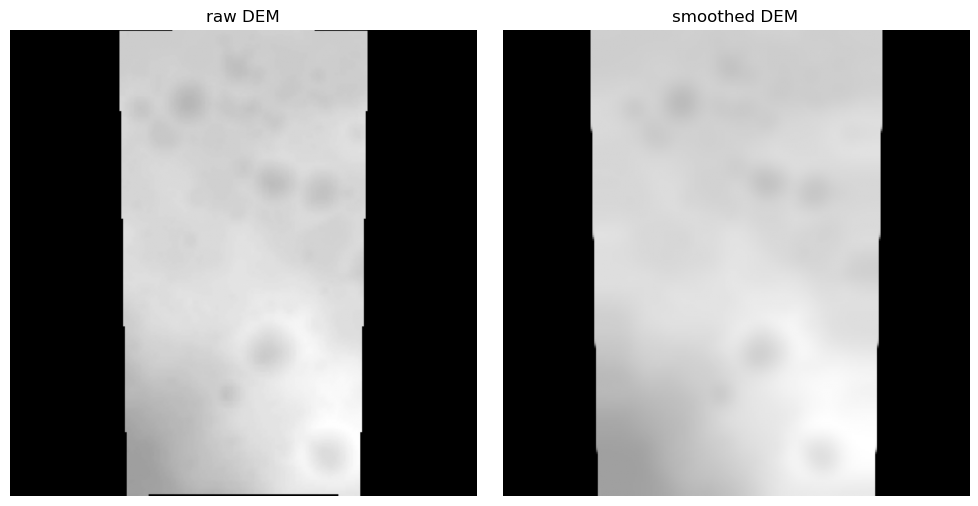

In [7]:
raw_mask = raw_data_mask(demo_tile['dem'])
valid_mask = valid_data_mask(demo_tile['dem'])
dem_smooth = masked_gaussian(demo_tile['dem'], raw_mask, SIGMA_SMOOTH)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(demo_tile['dem'], cmap='gray'); ax[0].set_title('raw DEM')
ax[1].imshow(dem_smooth, cmap='gray');       ax[1].set_title('smoothed DEM')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 2: Sobel gradient magnitude, then binarized at `BASELINE_EDGE_PERCENTILE`.

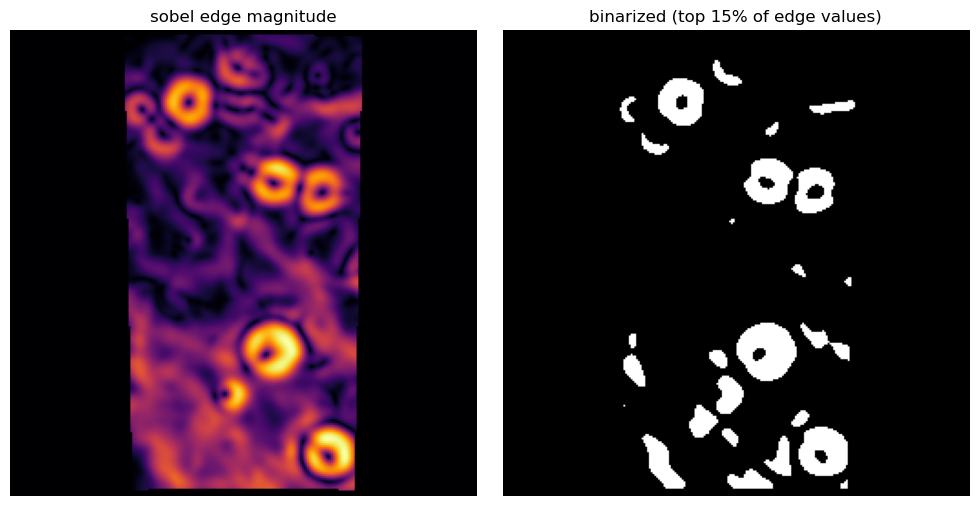

In [8]:
edge = sobel(dem_smooth) * valid_mask
edge_binary = (edge > np.percentile(edge[valid_mask], BASELINE_EDGE_PERCENTILE)) & valid_mask

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(edge, cmap='inferno');     ax[0].set_title('sobel edge magnitude')
ax[1].imshow(edge_binary, cmap='gray'); ax[1].set_title(f'binarized (top {100-BASELINE_EDGE_PERCENTILE}% of edge values)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 3: the raw circles Hough finds

In [9]:
raw_dets = hough_raw(demo_tile['dem'])

Step 4: `circle_nms` removes duplicates: for each cluster of overlapping circles, keep only the highest-scoring one. `BASELINE_OVERLAP_THRESH` controls how much overlap counts as "the same crater".

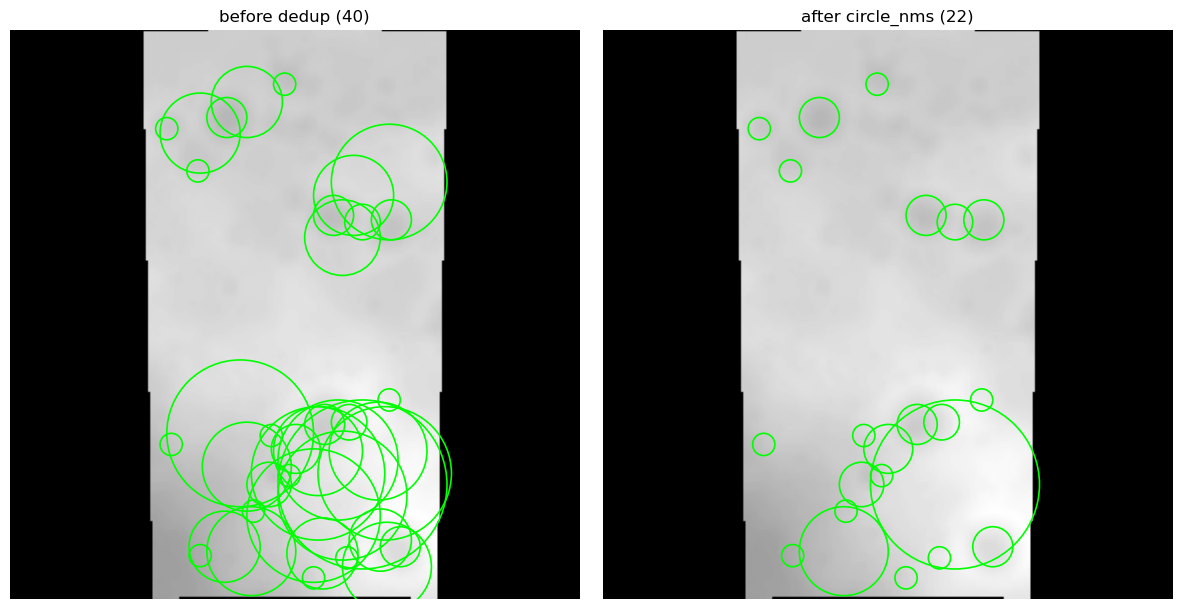

In [10]:
deduped_dets = circle_nms(raw_dets, overlap_thresh=BASELINE_OVERLAP_THRESH)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(demo_tile['dem'], cmap='gray')
for cy, cx, r, s in raw_dets:
    ax[0].add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.2))
ax[0].set_title(f'before dedup ({len(raw_dets)})')

ax[1].imshow(demo_tile['dem'], cmap='gray')
for cy, cx, r, s in deduped_dets:
    ax[1].add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.2))
ax[1].set_title(f'after circle_nms ({len(deduped_dets)})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


In [11]:
evaluate_method(detect_baseline, label='baseline (sobel+hough)')

=== baseline (sobel+hough) ===
precision : 0.11
recall    : 0.46
F1        : 0.18
TP=1471   FP=11593   FN=1761


### Code Structure
```
evaluate_method(detect_baseline, ...)
└─ for each of the 100 tiles:
   ├─ detect_fn(dem) == detect_baseline(dem)
   │  ├─ hough_raw(dem)
   │  │  ├─ raw_data_mask(dem)
   │  │  ├─ valid_data_mask(dem) → calls raw_data_mask(dem) again itself
   │  │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  │  ├─ sobel(dem_smooth)
   │  │  ├─ hough_circle(...)
   │  │  └─ hough_circle_peaks(...)
   │  └─ circle_nms(dets)
   └─ match_detailed(dets, craters)
└─ (after all 100 runs) compute precision/recall/F1 + print
```


## Method A: Slope

Rim candidates from thresholding slope magnitude, radius from a kernel(interior)/annulus(rim) scan.

In [12]:
RELIEF_SIGMA = 10 # regional-trend smoothing scale for relief
A_RIM_THRESHOLD = 0.60 # slope score above this counts as a rim pixel
A_CLOSING_ITERS = 2 # how many pixels of gap in the rim get bridged before labelling
A_MIN_REGION_PX = 5 # rim regions smaller than this counted as not a real ring
A_MIN_SHAPE_CIRCULARITY = 0.45 # filled-in region must be at least this circular (1.0 = perfect circle)
A_DETECTION_THRESHOLD = 0.3 # combined kernel+ring score must clear this to count as a detection

# local relief: how much higher/lower a pixel is than the smoothed regional trend around it.
# negative inside a crater floor, positive on the rim
def compute_relief(dem_smooth, raw_mask, valid_mask, sigma=RELIEF_SIGMA):
    trend = masked_gaussian(dem_smooth, raw_mask, sigma) # calls masked_gaussian(), large sigma this time
    return (dem_smooth - trend) * valid_mask

# steepness at every pixel from the elevation gradient: high on crater walls, low on flat ground
def slope_magnitude(dem, valid_mask):
    dy, dx = np.gradient(dem)
    return np.sqrt(dx**2 + dy**2) * valid_mask

# builds a filled circle mask: True for every pixel inside a circle of radius r around (cy, cx)
def disk_mask(cy, cx, r, shape):
    y, x = np.ogrid[:shape[0], :shape[1]] # coordinate grids for the whole image
    return (y-cy)**2 + (x-cx)**2 <= r**2 # pixel is inside the circle if its distance to (cy,cx) is <= r

# builds a ring mask: True for every pixel between an inner and an outer circle around (cy, cx)
def annulus_mask(cy, cx, r_in, r_out, shape):
    y, x = np.ogrid[:shape[0], :shape[1]]
    d2 = (y-cy)**2 + (x-cx)**2 # squared distance of every pixel to (cy,cx)
    return (d2 >= r_in**2) & (d2 <= r_out**2) # pixel is inside the ring if it's outside r_in but inside r_out

def circularity(area, perimeter):
    perimeter = perimeter if perimeter > 0 else 1e-6 # avoid a divide-by-zero on a 1-pixel region
    return 4*np.pi*area / (perimeter**2)

# turns the rim signal into a list of candidate crater centres: threshold, close small gaps,
# label the resulting rings, and keep only the ones whose filled-in shape is circular enough
def find_rim_centres(score_rim, valid_mask):
    rim_binary = (score_rim > A_RIM_THRESHOLD) & valid_mask # threshold -> boolean rim mask
    rim_closed = ndimage.binary_closing(rim_binary, iterations=A_CLOSING_ITERS) # scipy: bridges small gaps
    labels, n_regions = ndimage.label(rim_closed) # scipy: connected components, one id per ring
    centres = []
    for region_id in range(1, n_regions + 1):
        region_mask = labels == region_id
        if region_mask.sum() < A_MIN_REGION_PX:
            continue # too small to be a real rim, likely noise
        filled = ndimage.binary_fill_holes(region_mask) # scipy: fills the ring's hole into a solid disk
        props = regionprops(label(filled)) # skimage: measures the filled shape
        if not props or circularity(props[0].area, props[0].perimeter) < A_MIN_SHAPE_CIRCULARITY:
            continue # calls circularity()
        cy, cx = ndimage.center_of_mass(region_mask) # scipy: centroid of the (unfilled) ring
        centres.append((int(round(cy)), int(round(cx))))
    return centres

# for each candidate centre, tries every radius and keeps the one where the interior (kernel disk)
# and the rim (annulus ring) both score highest at the same time
def radius_scan_and_filter(candidates, score_int, score_rim, valid_mask,
                            radii=range(5, 60, 1), detection_threshold=A_DETECTION_THRESHOLD):
    detections = []
    for cy, cx in candidates:
        best_r, best_score = None, -1
        for r in radii:
            k_mask = disk_mask(cy, cx, 0.7*r, score_int.shape) & valid_mask # calls disk_mask()
            if not k_mask.any():
                continue
            kern = score_int[k_mask].mean() # average interior score inside the disk
            ann_mask = annulus_mask(cy, cx, 0.8*r, 1.2*r, score_int.shape) & valid_mask # calls annulus_mask()
            if not ann_mask.any():
                continue
            ring = score_rim[ann_mask].mean() # average rim score inside the annulus
            total = 0.5*kern + 0.5*ring
            if total > best_score:
                best_score, best_r = total, r
        if best_score is not None and best_score > detection_threshold:
            detections.append((cy, cx, best_r, best_score))
    return circle_nms(detections) # calls circle_nms()

# Method A end to end: slope as the rim signal, relief as the interior signal
def detect_A_slope(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    relief = compute_relief(dem_smooth, raw_mask, valid_mask) # calls compute_relief()
    score_int = normalize(relief, invert=True, mask=valid_mask) # calls normalize() and inverts
    score_rim = normalize(slope_magnitude(dem_smooth, valid_mask), mask=valid_mask) # calls slope_magnitude(), normalize()
    candidates = find_rim_centres(score_rim, valid_mask) # calls find_rim_centres()
    return radius_scan_and_filter(candidates, score_int, score_rim, valid_mask, detection_threshold=A_DETECTION_THRESHOLD) # calls radius_scan_and_filter()


Step 1: relief (interior) and slope (rim), both from the smoothed DEM.

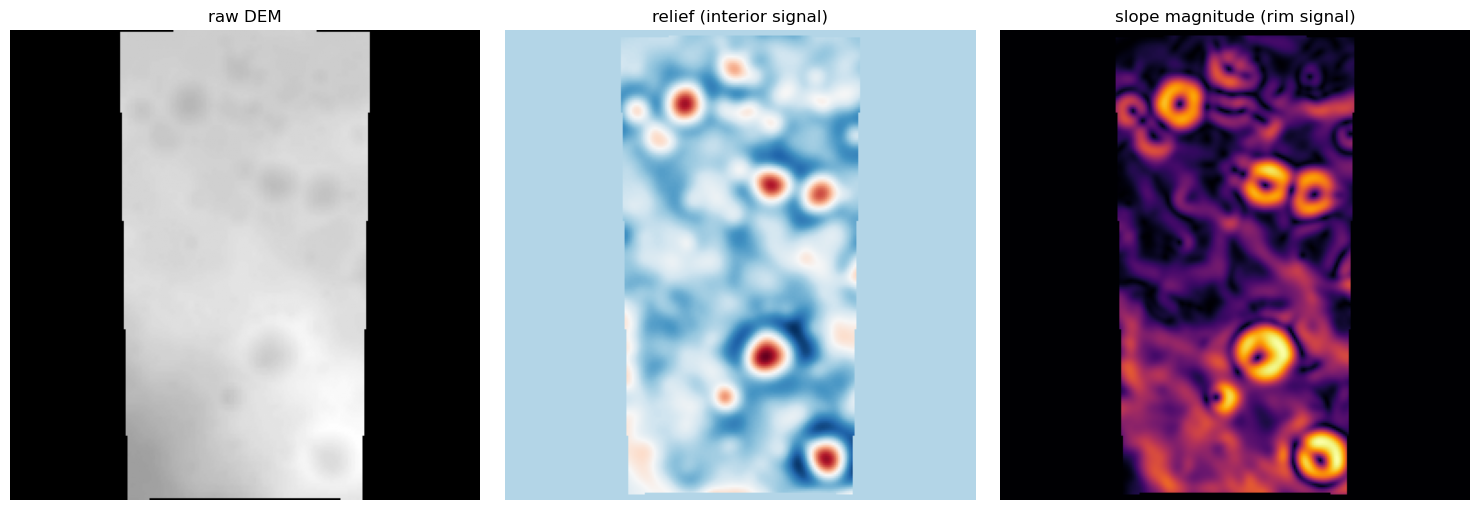

In [13]:
raw_mask = raw_data_mask(demo_tile['dem'])
valid_mask = valid_data_mask(demo_tile['dem'])
dem_smooth = masked_gaussian(demo_tile['dem'], raw_mask, SIGMA_SMOOTH)
relief = compute_relief(dem_smooth, raw_mask, valid_mask)
slope = slope_magnitude(dem_smooth, valid_mask)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(demo_tile['dem'], cmap='gray'); ax[0].set_title('raw DEM')
ax[1].imshow(relief, cmap='RdBu');           ax[1].set_title('relief (interior signal)')
ax[2].imshow(slope, cmap='inferno');         ax[2].set_title('slope magnitude (rim signal)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 2: both normalized to [0,1], then the rim signal thresholded at `A_RIM_THRESHOLD`.

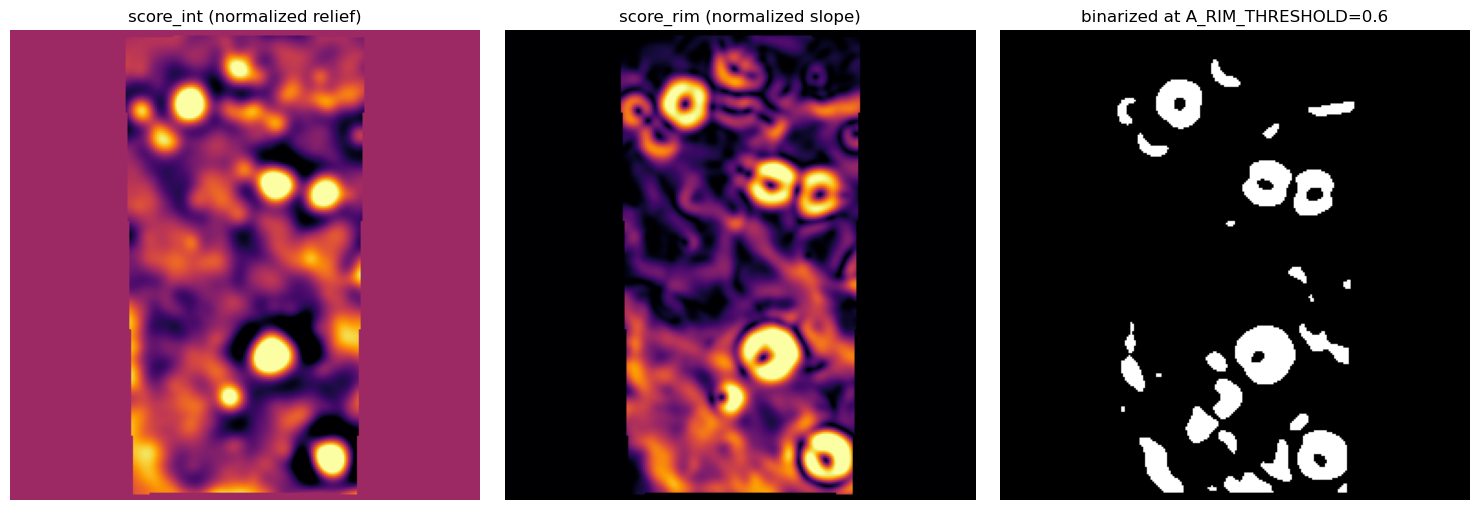

In [14]:
score_int = normalize(relief, invert=True, mask=valid_mask)
score_rim = normalize(slope, mask=valid_mask)
rim_binary = (score_rim > A_RIM_THRESHOLD) & valid_mask

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(score_int, cmap='inferno'); ax[0].set_title('score_int (normalized relief)')
ax[1].imshow(score_rim, cmap='inferno'); ax[1].set_title('score_rim (normalized slope)')
ax[2].imshow(rim_binary, cmap='gray');   ax[2].set_title(f'binarized at A_RIM_THRESHOLD={A_RIM_THRESHOLD}')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 3: close small gaps (`A_CLOSING_ITERS`), then label connected rings and keep only circular enough ones (`A_MIN_REGION_PX`, `A_MIN_SHAPE_CIRCULARITY`). Surviving centroids become candidate centres.

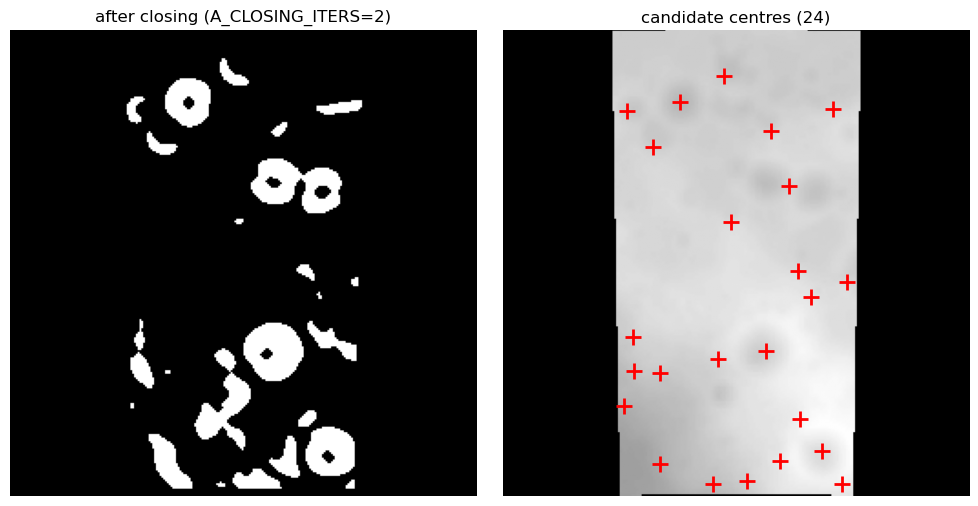

In [15]:
rim_closed = ndimage.binary_closing(rim_binary, iterations=A_CLOSING_ITERS)
candidates = find_rim_centres(score_rim, valid_mask)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(rim_closed, cmap='gray'); ax[0].set_title(f'after closing (A_CLOSING_ITERS={A_CLOSING_ITERS})')
ax[1].imshow(demo_tile['dem'], cmap='gray')
for cy, cx in candidates:
    ax[1].plot(cx, cy, 'r+', markersize=12, mew=2)
ax[1].set_title(f'candidate centres ({len(candidates)})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 4: for one candidate, the actual radius scan: kernel disk (interior) at `0.7r`, annulus ring (rim) at `0.8r-1.2r`, for the winning radius.

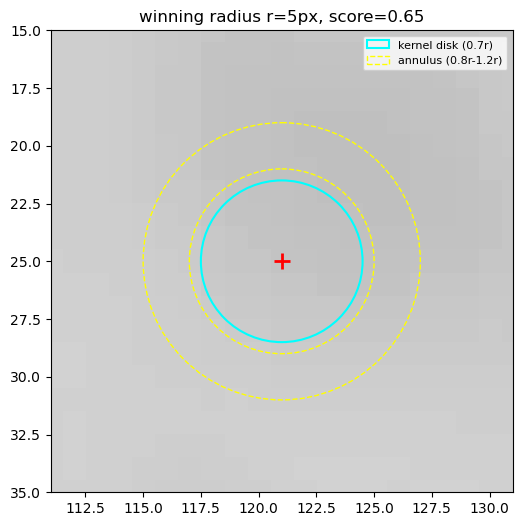

In [16]:
if candidates:
    cy, cx = candidates[0]
    best_r, best_score = None, -1
    for r in range(5, 60, 1):
        k_mask = disk_mask(cy, cx, 0.7*r, score_int.shape) & valid_mask
        ann_mask = annulus_mask(cy, cx, 0.8*r, 1.2*r, score_int.shape) & valid_mask
        if not k_mask.any() or not ann_mask.any(): continue
        total = 0.5*score_int[k_mask].mean() + 0.5*score_rim[ann_mask].mean()
        if total > best_score:
            best_score, best_r = total, r

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(demo_tile['dem'], cmap='gray')
    ax.add_patch(Circle((cx, cy), 0.7*best_r, fill=False, color='cyan', lw=1.5, label='kernel disk (0.7r)'))
    ax.add_patch(Circle((cx, cy), 0.8*best_r, fill=False, color='yellow', lw=1, linestyle='--'))
    ax.add_patch(Circle((cx, cy), 1.2*best_r, fill=False, color='yellow', lw=1, linestyle='--', label='annulus (0.8r-1.2r)'))
    ax.plot(cx, cy, 'r+', markersize=12, mew=2)
    ax.set_xlim(cx-2*best_r, cx+2*best_r); ax.set_ylim(cy+2*best_r, cy-2*best_r)
    ax.set_title(f'winning radius r={best_r}px, score={best_score:.2f}')
    ax.legend(loc='upper right', fontsize=8)
    plt.show()
else:
    print('no candidates on this demo tile')


In [17]:
evaluate_method(detect_A_slope, label='A slope')

=== A slope ===
precision : 0.19
recall    : 0.26
F1        : 0.22
TP=842   FP=3585   FN=2390


### Code structure
```
evaluate_method(detect_A_slope, ...)
└─ for each of the 100 tiles:
   ├─ detect_fn(dem)  ==  detect_A_slope(dem)
   │  ├─ raw_data_mask(dem)
   │  ├─ valid_data_mask(dem) → calls raw_data_mask(dem) again itself
   │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  ├─ compute_relief(dem_smooth, raw_mask, valid_mask)
   │  │  └─ masked_gaussian(dem_smooth, raw_mask, sigma)
   │  ├─ normalize(relief, invert=True)  → score_int
   │  ├─ slope_magnitude(dem_smooth, valid_mask)
   │  ├─ normalize(slope, ...)  → score_rim
   │  ├─ find_rim_centres(score_rim, valid_mask)
   │  │  ├─ binary_closing(...)
   │  │  ├─ label(...)
   │  │  ├─ binary_fill_holes(...)
   │  │  ├─ regionprops(...)
   │  │  └─ circularity(area, perimeter)
   │  └─ radius_scan_and_filter(candidates, score_int, score_rim, valid_mask)
   │     ├─ for each candidate, for each radius:
   │     │  ├─ disk_mask(cy, cx, 0.7*r, ...)
   │     │  └─ annulus_mask(cy, cx, 0.8*r, 1.2*r, ...)
   │     └─ circle_nms(detections)
   └─ match_detailed(dets, craters)
└─ (after all 100 runs) compute precision/recall/F1 + print
```

## Method B: Flow accumulation (fill-depth)

Fill depressions on the detrended relief signal via topotoolbox. A closed depression has positive fill-depth; a through-flowing valley has none.

In [18]:
C_THRESHOLD_PERCENTILE = 90 # fill-depth values above this percentile count as "inside a crater"
C_MIN_AREA_PX = 12
C_MAX_AREA_PX = int(np.pi * SCAN_R_MAX**2)
C_MIN_CIRCULARITY = 0.3

# local relief: how much higher/lower a pixel is than the smoothed regional trend around it
def compute_relief(dem_smooth, raw_mask, valid_mask, sigma=10):
    trend = masked_gaussian(dem_smooth, raw_mask, sigma) # calls masked_gaussian()
    return (dem_smooth - trend) * valid_mask

# 1.0 for a perfect circle, lower for anything elongated or irregular
def circularity(area, perimeter):
    perimeter = perimeter if perimeter > 0 else 1e-6
    return 4*np.pi*area / (perimeter**2)

# fills every closed depression in a field via topotoolbox.
# padding is walled off to a very high value first, so filling never leaks into it
def fill_depressions(field, raw_mask):
    walled = np.where(raw_mask, field, field.max() + 1000).astype('float32') # wall off padding
    g = tt3.GridObject()
    g.z = walled
    g.cellsize = 60.0
    filled = g.fillsinks() # topotoolbox: fills every depression up to its lowest outflow point
    return np.asarray(filled.z)

# how much a pixel got filled: positive only inside a genuinely closed depression, exactly
# zero on a through-flowing valley. that's the flow-accumulation-relevant property of a crater floor
def compute_fill_depth(relief, raw_mask, valid_mask):
    filled = fill_depressions(relief, raw_mask) # calls fill_depressions()
    return (filled - relief) * valid_mask

# thresholds a signal, labels the resulting blobs, and keeps the ones that are a plausible
# crater size and circular enough
def interior_blob_detect(signal, valid_mask):
    cutoff = np.percentile(signal[valid_mask], C_THRESHOLD_PERCENTILE)
    blob_binary = (signal > cutoff) & valid_mask
    labels, n_regions = ndimage.label(blob_binary)
    detections = []
    for region in regionprops(labels): # measure each blob
        if region.area < C_MIN_AREA_PX or region.area > C_MAX_AREA_PX:
            continue
        circ = circularity(region.area, region.perimeter) # calls circularity()
        if circ < C_MIN_CIRCULARITY:
            continue
        cy, cx = region.centroid # this is the detection's centre
        detections.append((cy, cx, np.sqrt(region.area/np.pi), circ)) # radius from the blob's area
    return circle_nms(detections) # calls circle_nms()

# Method C end to end: fill-depth of the detrended relief signal marks closed depressions directly
def detect_C_flow_accum(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    relief = compute_relief(dem_smooth, raw_mask, valid_mask) # calls compute_relief()
    depth = compute_fill_depth(relief, raw_mask, valid_mask) # calls compute_fill_depth()
    return interior_blob_detect(depth, valid_mask) # calls interior_blob_detect()


Step 1: relief (detrended), then the fill-depth of that relief.

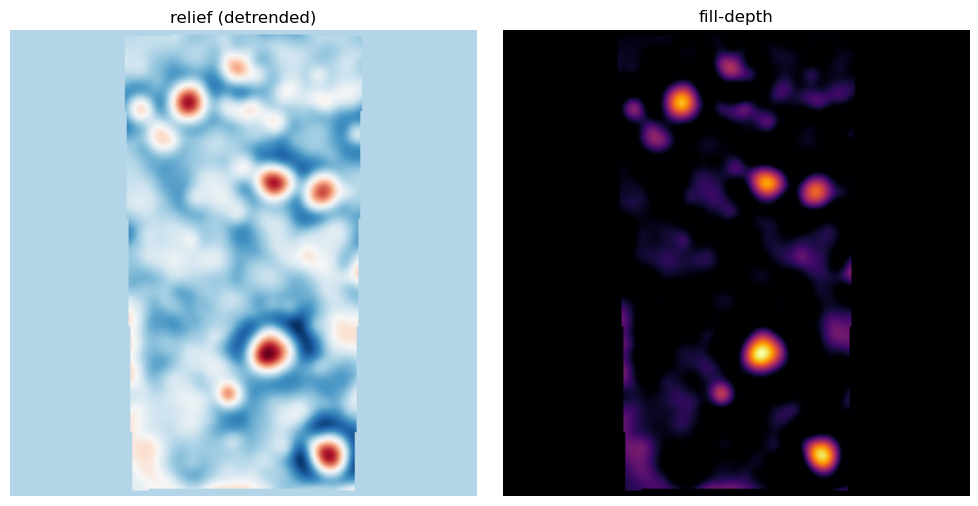

In [19]:
raw_mask = raw_data_mask(demo_tile['dem'])
valid_mask = valid_data_mask(demo_tile['dem'])
dem_smooth = masked_gaussian(demo_tile['dem'], raw_mask, SIGMA_SMOOTH)
relief = compute_relief(dem_smooth, raw_mask, valid_mask)
depth = compute_fill_depth(relief, raw_mask, valid_mask)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(relief, cmap='RdBu');   ax[0].set_title('relief (detrended)')
ax[1].imshow(depth, cmap='inferno'); ax[1].set_title('fill-depth')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 2: threshold fill-depth at `C_THRESHOLD_PERCENTILE`, label the resulting blobs, mark their centroids.

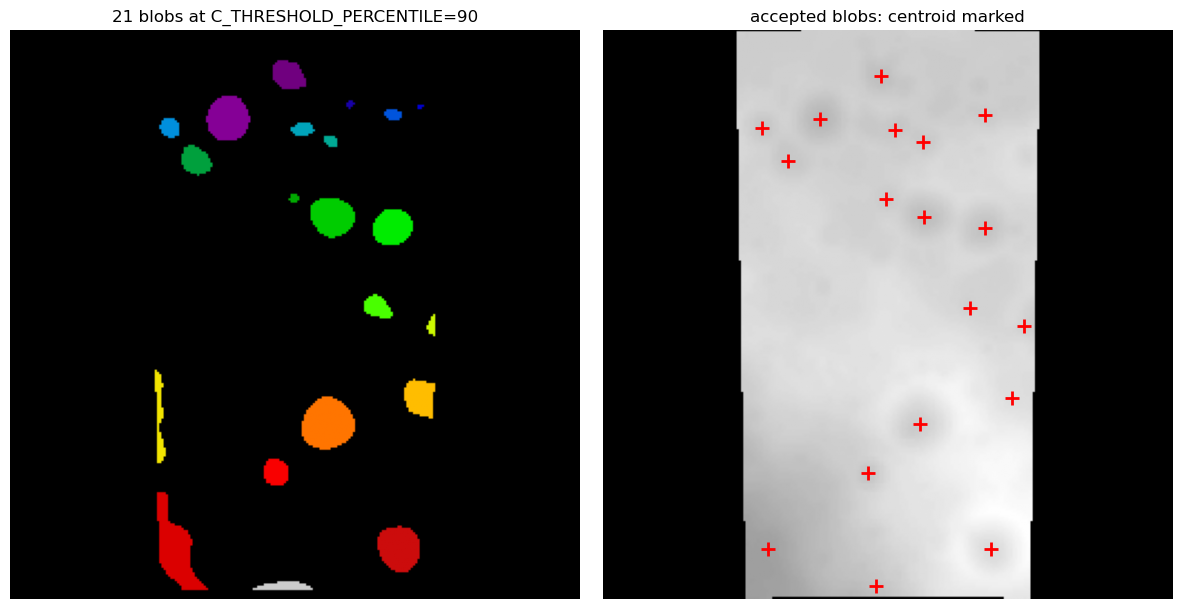

In [20]:
cutoff = np.percentile(depth[valid_mask], C_THRESHOLD_PERCENTILE)
blob_binary = (depth > cutoff) & valid_mask
labels_img, n_blobs = ndimage.label(blob_binary)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(labels_img, cmap='nipy_spectral'); ax[0].set_title(f'{n_blobs} blobs at C_THRESHOLD_PERCENTILE={C_THRESHOLD_PERCENTILE}')
ax[1].imshow(demo_tile['dem'], cmap='gray')
for region in regionprops(labels_img):
    if region.area < C_MIN_AREA_PX or region.area > C_MAX_AREA_PX:
        continue
    if circularity(region.area, region.perimeter) < C_MIN_CIRCULARITY:
        continue
    cy, cx = region.centroid
    ax[1].plot(cx, cy, 'r+', markersize=10, mew=2)
ax[1].set_title('accepted blobs: centroid marked')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


In [21]:
evaluate_method(detect_C_flow_accum, label='C flow accumulation')


=== C flow accumulation ===
precision : 0.23
recall    : 0.56
F1        : 0.33
TP=1796   FP=5967   FN=1436


### Code Structure
```
evaluate_method(detect_C_flow_accum, ...)
└─ for each of the 100 tiles:
   ├─ detect_fn(dem)  ==  detect_C_flow_accum(dem)
   │  ├─ raw_data_mask(dem)
   │  ├─ valid_data_mask(dem) → calls raw_data_mask(dem) again itself
   │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  ├─ compute_relief(dem_smooth, raw_mask, valid_mask)
   │  │  └─ masked_gaussian(dem_smooth, raw_mask, sigma)
   │  ├─ compute_fill_depth(relief, raw_mask, valid_mask)
   │  │  └─ fill_depressions(relief, raw_mask)
   │  │     └─ g.fillsinks()   [topotoolbox]
   │  └─ interior_blob_detect(depth, valid_mask)
   │     ├─ label(blob_binary)                         [scipy]
   │     ├─ regionprops(labels)                         [skimage]
   │     ├─ circularity(area, perimeter)
   │     └─ circle_nms(detections)
   └─ match_detailed(dets, craters)
└─ (after all 100 runs) compute precision/recall/F1 + print
```


## Method C: Flow direction (D8 sinks)

Each pixel points to its steepest of 8 neighbours. A pixel with no valid downhill neighbour is a topological sink, marks a crater floor directly.

In [22]:
E_MIN_REGION_PX = 1 # sinks are inherently single-pixel
E_DETECTION_THRESHOLD = 0.6

D8_OFFSETS = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)] # the 8 neighbour directions
D8_DISTS = [np.sqrt(2),1,np.sqrt(2),1,1,np.sqrt(2),1,np.sqrt(2)] # matching distance to each neighbour

# local relief: how much higher/lower a pixel is than the smoothed regional trend around it
def compute_relief(dem_smooth, raw_mask, valid_mask, sigma=10):
    trend = masked_gaussian(dem_smooth, raw_mask, sigma) # calls masked_gaussian()
    return (dem_smooth - trend) * valid_mask

# steepness at every pixel -- high on crater walls, low on flat ground
def slope_magnitude(dem, valid_mask):
    dy, dx = np.gradient(dem)
    return np.sqrt(dx**2 + dy**2) * valid_mask

# boolean disk of radius r around (cy, cx)
def disk_mask(cy, cx, r, shape):
    y, x = np.ogrid[:shape[0], :shape[1]]
    return (y-cy)**2 + (x-cx)**2 <= r**2

# boolean ring between r_in and r_out around (cy, cx)
def annulus_mask(cy, cx, r_in, r_out, shape):
    y, x = np.ogrid[:shape[0], :shape[1]]
    d2 = (y-cy)**2 + (x-cx)**2
    return (d2 >= r_in**2) & (d2 <= r_out**2)

# same radius-scan logic as Method A -- own copy so this section stays self-contained
def radius_scan_and_filter(candidates, score_int, score_rim, valid_mask,
                            radii=range(5, 60, 1), detection_threshold=E_DETECTION_THRESHOLD):
    detections = []
    for cy, cx in candidates:
        best_r, best_score = None, -1
        for r in radii:
            k_mask = disk_mask(cy, cx, 0.7*r, score_int.shape) & valid_mask # calls disk_mask()
            if not k_mask.any():
                continue
            kern = score_int[k_mask].mean()
            ann_mask = annulus_mask(cy, cx, 0.8*r, 1.2*r, score_int.shape) & valid_mask # calls annulus_mask()
            if not ann_mask.any():
                continue
            ring = score_rim[ann_mask].mean()
            total = 0.5*kern + 0.5*ring
            if total > best_score:
                best_score, best_r = total, r
        if best_score is not None and best_score > detection_threshold:
            detections.append((cy, cx, best_r, best_score))
    return circle_nms(detections) # calls circle_nms()

# for every pixel, finds the steepest of its 8 neighbours (D8 routing). a pixel that has no
# neighbour lower than itself gets direction -1 -- it's a topological sink
def d8_flow_direction(filled_dem, valid_mask):
    direction = np.full(filled_dem.shape, -1, dtype=int) # -1 = no downhill neighbour found yet
    best_drop = np.zeros(filled_dem.shape) # steepest drop found so far, per pixel
    for k, (dy, dx) in enumerate(D8_OFFSETS):
        shifted = np.roll(np.roll(filled_dem, -dy, axis=0), -dx, axis=1) # this neighbour's elevation
        drop = (filled_dem - shifted) / D8_DISTS[k] # how much lower that neighbour is
        valid_neighbour = np.roll(np.roll(valid_mask, -dy, axis=0), -dx, axis=1)
        better = (drop > best_drop) & valid_neighbour & valid_mask # this neighbour beats the previous best
        direction[better] = k # remember which of the 8 directions is currently steepest
        best_drop = np.where(better, drop, best_drop)
    return direction

# Method E end to end: D8 sinks become candidate centres, then the same kernel/annulus scan as A
def detect_E_flow_direction(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    relief = compute_relief(dem_smooth, raw_mask, valid_mask) # calls compute_relief()
    direction = d8_flow_direction(dem_smooth, valid_mask) # calls d8_flow_direction()
    sinks = (direction == -1) & valid_mask # no downhill neighbour = sink = candidate crater floor
    labels, n = ndimage.label(sinks) # scipy: label each sink
    candidates = []
    for region_id in range(1, n+1):
        region_mask = labels == region_id
        if region_mask.sum() < E_MIN_REGION_PX:
            continue
        cy, cx = ndimage.center_of_mass(region_mask) # scipy: sink centroid
        candidates.append((int(round(cy)), int(round(cx))))
    score_int = normalize(relief, invert=True, mask=valid_mask) # calls normalize()
    score_rim = normalize(slope_magnitude(dem_smooth, valid_mask), mask=valid_mask) # calls slope_magnitude(), normalize()
    return radius_scan_and_filter(candidates, score_int, score_rim, valid_mask, detection_threshold=E_DETECTION_THRESHOLD) # calls radius_scan_and_filter()


Step 1: all D8 sinks across the whole tile, marked on the DEM.

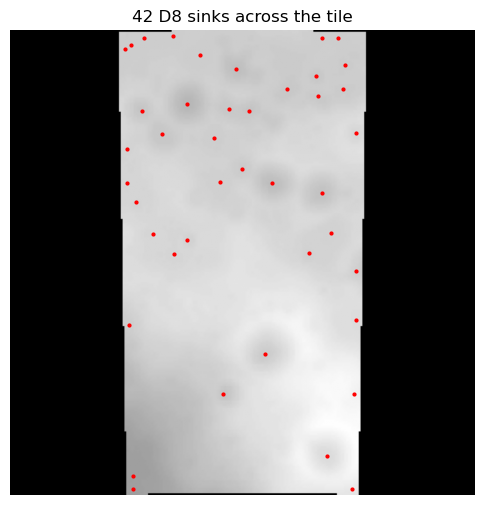

In [23]:
raw_mask = raw_data_mask(demo_tile['dem'])
valid_mask = valid_data_mask(demo_tile['dem'])
dem_smooth = masked_gaussian(demo_tile['dem'], raw_mask, SIGMA_SMOOTH)
relief = compute_relief(dem_smooth, raw_mask, valid_mask)
direction = d8_flow_direction(dem_smooth, valid_mask)
sinks = (direction == -1) & valid_mask

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(demo_tile['dem'], cmap='gray')
ys, xs = np.where(sinks)
ax.plot(xs, ys, 'r.', markersize=4)
ax.set_title(f'{len(ys)} D8 sinks across the tile')
ax.axis('off')
plt.show()


Step 2: zoomed in around one cluster of sinks, with the actual per-pixel flow direction drawn as arrows.

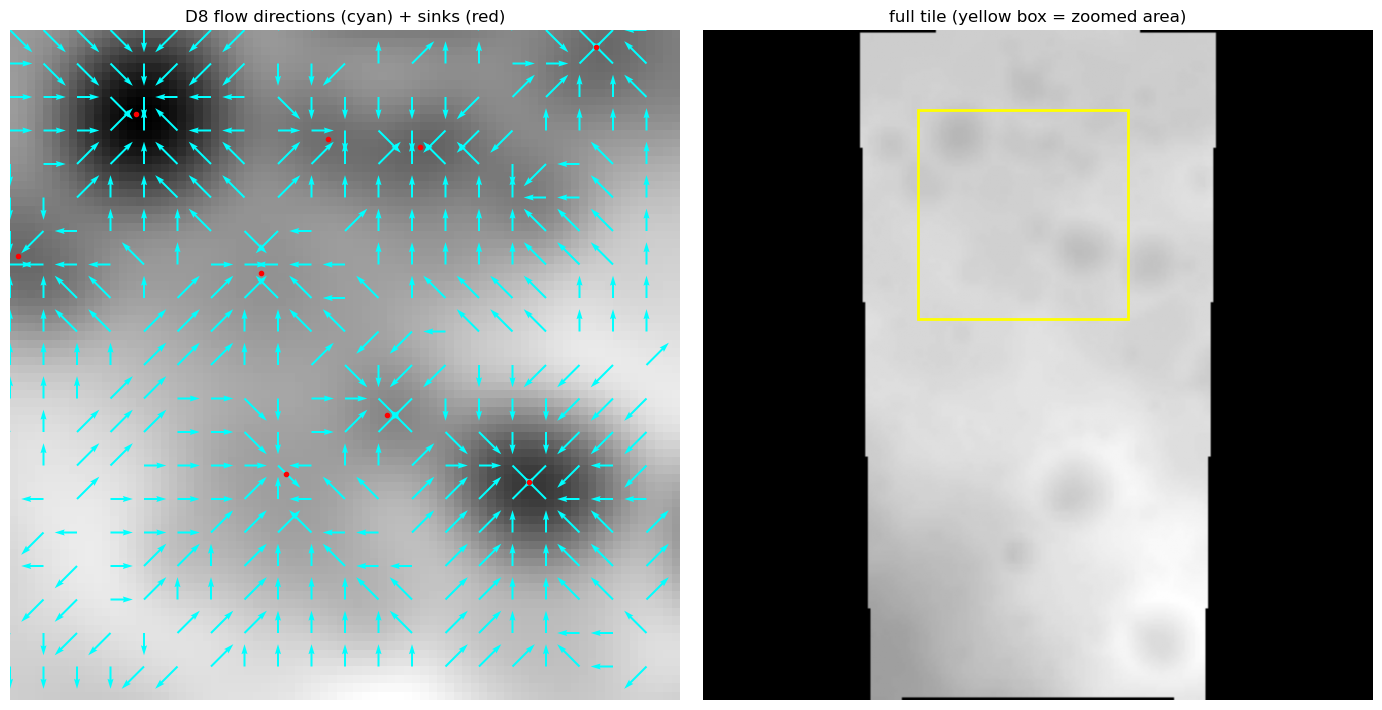

In [24]:
ys, xs = np.where(sinks)
cy0, cx0 = (int(np.median(ys)), int(np.median(xs))) if len(ys) else (dem_smooth.shape[0]//2, dem_smooth.shape[1]//2)
half = 40
y0, y1 = max(0, cy0-half), min(dem_smooth.shape[0], cy0+half)
x0, x1 = max(0, cx0-half), min(dem_smooth.shape[1], cx0+half)

step = 4
yy, xx = np.mgrid[y0:y1:step, x0:x1:step]
uu = np.zeros_like(yy, dtype=float); vv = np.zeros_like(yy, dtype=float)
for i in range(yy.shape[0]):
    for j in range(yy.shape[1]):
        k = direction[yy[i,j], xx[i,j]]
        if k >= 0:
            dyk, dxk = D8_OFFSETS[k]
            uu[i,j], vv[i,j] = dxk, dyk

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(dem_smooth[y0:y1, x0:x1], cmap='gray', extent=[x0, x1, y1, y0])
ax[0].quiver(xx, yy, uu, -vv, color='cyan', scale=30)
sy, sx = np.where(sinks[y0:y1, x0:x1])
ax[0].plot(sx+x0, sy+y0, 'r.', markersize=6)
ax[0].set_title('D8 flow directions (cyan) + sinks (red)')
ax[0].axis('off')
ax[1].imshow(demo_tile['dem'], cmap='gray')
ax[1].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, color='yellow', lw=2))
ax[1].set_title('full tile (yellow box = zoomed area)')
ax[1].axis('off')
plt.tight_layout(); plt.show()


Step 3: for one sink, the same kernel/annulus radius scan as Method A.

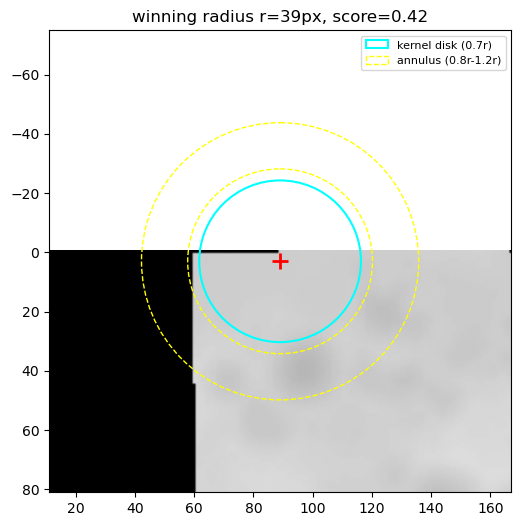

In [25]:
labels_e, n_e = ndimage.label(sinks)
candidates_e = [tuple(map(int, map(round, ndimage.center_of_mass(labels_e == i)))) for i in range(1, n_e+1)]

score_int = normalize(relief, invert=True, mask=valid_mask)
score_rim = normalize(slope_magnitude(dem_smooth, valid_mask), mask=valid_mask)

if candidates_e:
    cy, cx = candidates_e[0]
    best_r, best_score = None, -1
    for r in range(5, 60, 1):
        k_mask = disk_mask(cy, cx, 0.7*r, score_int.shape) & valid_mask
        ann_mask = annulus_mask(cy, cx, 0.8*r, 1.2*r, score_int.shape) & valid_mask
        if not k_mask.any() or not ann_mask.any(): continue
        total = 0.5*score_int[k_mask].mean() + 0.5*score_rim[ann_mask].mean()
        if total > best_score:
            best_score, best_r = total, r

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(demo_tile['dem'], cmap='gray')
    ax.add_patch(Circle((cx, cy), 0.7*best_r, fill=False, color='cyan', lw=1.5, label='kernel disk (0.7r)'))
    ax.add_patch(Circle((cx, cy), 0.8*best_r, fill=False, color='yellow', lw=1, linestyle='--'))
    ax.add_patch(Circle((cx, cy), 1.2*best_r, fill=False, color='yellow', lw=1, linestyle='--', label='annulus (0.8r-1.2r)'))
    ax.plot(cx, cy, 'r+', markersize=12, mew=2)
    ax.set_xlim(cx-2*best_r, cx+2*best_r); ax.set_ylim(cy+2*best_r, cy-2*best_r)
    ax.set_title(f'winning radius r={best_r}px, score={best_score:.2f}')
    ax.legend(loc='upper right', fontsize=8)
    plt.show()
else:
    print('no sinks on this demo tile')


In [26]:
evaluate_method(detect_E_flow_direction, label='E flow direction')


=== E flow direction ===
precision : 0.42
recall    : 0.61
F1        : 0.50
TP=1958   FP=2655   FN=1274


### Code Structure
```
evaluate_method(detect_E_flow_direction, ...)
└─ for each of the 100 tiles:
   ├─ detect_fn(dem)  ==  detect_E_flow_direction(dem)
   │  ├─ raw_data_mask(dem)
   │  ├─ valid_data_mask(dem) → calls raw_data_mask(dem) again itself
   │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  ├─ compute_relief(dem_smooth, raw_mask, valid_mask)
   │  │  └─ masked_gaussian(dem_smooth, raw_mask, sigma)
   │  ├─ d8_flow_direction(dem_smooth, valid_mask)
   │  │  └─ for each of the 8 neighbour directions: steepest-descent check
   │  ├─ label(sinks)                              [scipy] → candidate centres (sink centroids)
   │  ├─ normalize(relief, invert=True)   → score_int
   │  ├─ slope_magnitude(dem_smooth, valid_mask)
   │  ├─ normalize(slope, ...)   → score_rim
   │  └─ radius_scan_and_filter(candidates, score_int, score_rim, valid_mask)
   │     ├─ for each candidate, for each radius:
   │     │  ├─ disk_mask(cy, cx, 0.7*r, ...)
   │     │  └─ annulus_mask(cy, cx, 0.8*r, 1.2*r, ...)
   │     └─ circle_nms(detections)
   └─ match_detailed(dets, craters)
└─ (after all 100 runs) compute precision/recall/F1 + print
```


## Method D: Sobel edge + watershed, without vs. with aspect filtering

Watershed floods the sobel gradient directly: flat interiors become basins, strong edges become the dividing ridges.

In [27]:
B_SOFT_THRESHOLD_PCT = 60 # edge values below this percentile are zeroed
B_H_MIN = 0.18 # minimum basin depth to count as a marker
B_MIN_AREA_PX = 30 # segments smaller than this are noise
B_MAX_AREA_PX = int(np.pi * SCAN_R_MAX**2) # tied to our scan range so it's never the bottleneck
B_MIN_CIRCULARITY = 0.5 # segment shape must be at least this circular

# sobel edge magnitude, masked so padding is never scored as an edge
def sobel_edge(dem, valid_mask):
    return sobel(dem) * valid_mask

# zeroes out weak values below a percentile cutoff, keeps real values above it
def soft_threshold(x, valid_mask, percentile=B_SOFT_THRESHOLD_PCT):
    cutoff = np.percentile(x[valid_mask], percentile)
    return np.where(x > cutoff, x, 0.0) * valid_mask

def circularity(area, perimeter):
    perimeter = perimeter if perimeter > 0 else 1e-6
    return 4*np.pi*area / (perimeter**2)

# floods the rim signal directly: flat interiors become basins, strong edges become the ridges that separate them
def watershed_on_gradient(score_rim, valid_mask):
    edge_search = np.where(valid_mask, score_rim, 1.0) # padding treated as an unfloodable wall
    minima = h_minima(edge_search, B_H_MIN) & valid_mask # skimage: regional minima -> seed markers
    markers, _ = ndimage.label(minima) # scipy: give each marker a unique id
    segments = watershed(edge_search, markers, mask=valid_mask) # skimage: flood outward from markers
    detections = []
    for region in regionprops(segments): # skimage: measure each resulting segment
        if region.area < B_MIN_AREA_PX or region.area > B_MAX_AREA_PX:
            continue
        circ = circularity(region.area, region.perimeter) # calls circularity()
        if circ < B_MIN_CIRCULARITY:
            continue
        cy, cx = region.centroid # this is the detection's centre
        detections.append((cy, cx, np.sqrt(region.area/np.pi), circ)) # radius from the segment's area
    return circle_nms(detections) # calls circle_nms()

# Method B end to end: sobel edge as the rim signal, watershed to segment floors from it
def detect_B_watershed(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    edge = sobel_edge(dem_smooth, valid_mask) # calls sobel_edge()
    score_rim = soft_threshold(normalize(edge, mask=valid_mask), valid_mask) # calls normalize(), soft_threshold()
    return watershed_on_gradient(score_rim, valid_mask) # calls watershed_on_gradient()


Step 1: sobel edge, then noise-gated at `B_SOFT_THRESHOLD_PCT` (values below the cutoff go to exactly 0, values above keep their real magnitude).

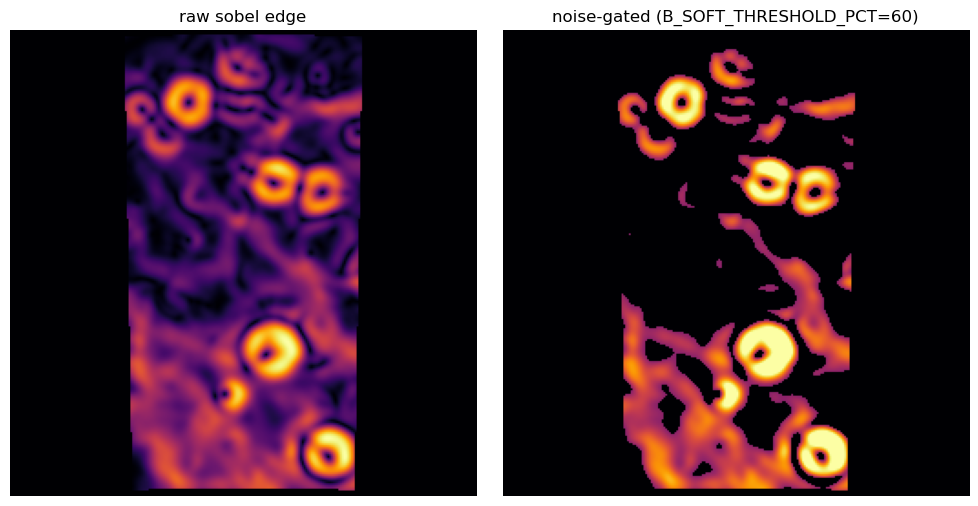

In [28]:
raw_mask = raw_data_mask(demo_tile['dem'])
valid_mask = valid_data_mask(demo_tile['dem'])
dem_smooth = masked_gaussian(demo_tile['dem'], raw_mask, SIGMA_SMOOTH)
edge = sobel_edge(dem_smooth, valid_mask)
score_rim = soft_threshold(normalize(edge, mask=valid_mask), valid_mask)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(edge, cmap='inferno');      ax[0].set_title('raw sobel edge')
ax[1].imshow(score_rim, cmap='inferno'); ax[1].set_title(f'noise-gated (B_SOFT_THRESHOLD_PCT={B_SOFT_THRESHOLD_PCT})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


Step 2: `h_minima` markers at `B_H_MIN`: these are the seed points watershed floods outward from.

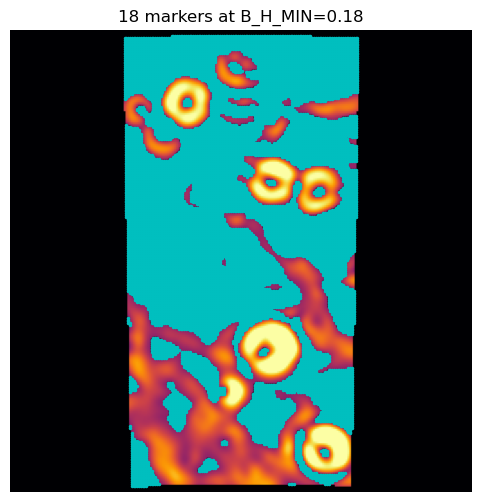

In [29]:
edge_search = np.where(valid_mask, score_rim, 1.0)
minima = h_minima(edge_search, B_H_MIN) & valid_mask

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(score_rim, cmap='inferno')
ys, xs = np.where(minima)
ax.plot(xs, ys, 'c.', markersize=3)
markers, n_markers = ndimage.label(minima)
ax.set_title(f'{n_markers} markers at B_H_MIN={B_H_MIN}')
ax.axis('off')
plt.show()


Step 3: the resulting watershed segments, with their centroids marked.

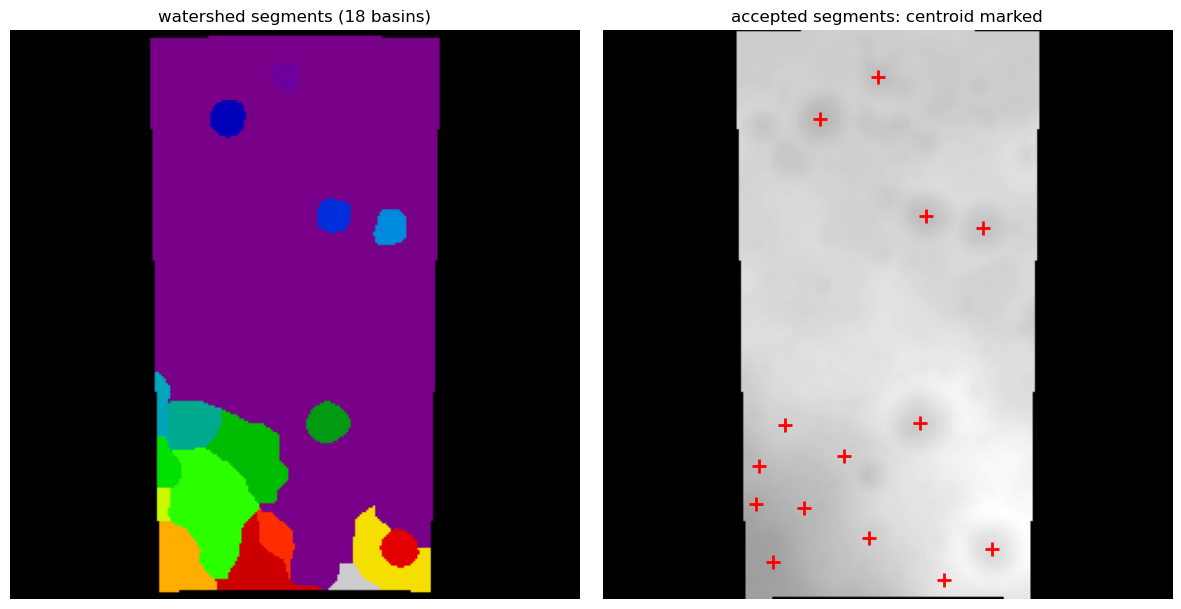

In [30]:
markers, _ = ndimage.label(minima)
segments = watershed(edge_search, markers, mask=valid_mask)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(segments, cmap='nipy_spectral')
ax[0].set_title(f'watershed segments ({segments.max()} basins)')

ax[1].imshow(demo_tile['dem'], cmap='gray')
for region in regionprops(segments):
    if region.area < B_MIN_AREA_PX or region.area > B_MAX_AREA_PX:
        continue
    circ = circularity(region.area, region.perimeter)
    if circ < B_MIN_CIRCULARITY:
        continue
    cy, cx = region.centroid
    ax[1].plot(cx, cy, 'r+', markersize=10, mew=2)
ax[1].set_title('accepted segments: centroid marked')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()


In [31]:
evaluate_method(detect_B_watershed, label='B sobel watershed (no aspect)')

=== B sobel watershed (no aspect) ===
precision : 0.22
recall    : 0.63
F1        : 0.33
TP=2041   FP=7222   FN=1191


### Method B + aspect filter

In [32]:
B_MIN_INWARD = 0.15 # average inward-pointing score a detection's rim must clear to survive

# samples the downslope direction at n_samples points around a ring of radius r. on a real
# crater rim, downslope points inward all the way around (average close to +1); on noise
# or a random edge it doesn't (average close to 0 or negative)
def aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask, n_samples=24):
    dy, dx = np.gradient(dem_smooth) # elevation gradient
    angles = np.linspace(0, 2*np.pi, n_samples, endpoint=False) # evenly spaced points around the ring
    inward = []
    for a in angles:
        py = int(round(cy + r*np.sin(a))) # sample point's row
        px = int(round(cx + r*np.cos(a))) # sample point's column
        if not (0 <= py < dem_smooth.shape[0] and 0 <= px < dem_smooth.shape[1]):
            continue
        if not valid_mask[py, px]:
            continue
        gy, gx = -dy[py, px], -dx[py, px] # downslope direction at this sample point
        norm = np.hypot(gy, gx) + 1e-9
        gy, gx = gy/norm, gx/norm # normalize to a unit vector
        iy, ix = (cy - py), (cx - px) # direction from the sample point toward the centre
        inorm = np.hypot(iy, ix) + 1e-9
        iy, ix = iy/inorm, ix/inorm
        inward.append(gy*iy + gx*ix) # dot product: +1 = perfectly inward, -1 = perfectly outward
    return np.mean(inward) if inward else 0.0

# drops any detection whose rim doesn't consistently point inward
def filter_by_aspect(detections, dem_smooth, valid_mask):
    kept = []
    for cy, cx, r, s in detections:
        if aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask) >= B_MIN_INWARD: # calls aspect_inward_consistency()
            kept.append((cy, cx, r, s))
    return kept

# Method B, cleaned up: take the plain watershed detections and drop the ones that fail the aspect check
def detect_B_aspect(dem):
    raw_mask = raw_data_mask(dem) # calls raw_data_mask()
    valid_mask = valid_data_mask(dem) # calls valid_data_mask()
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH) # calls masked_gaussian()
    dets = detect_B_watershed(dem) # calls detect_B_watershed()
    return filter_by_aspect(dets, dem_smooth, valid_mask) # calls filter_by_aspect() to clean it up


Looking for one real accepted example and one real rejected example, scanning actual detections across the first several tiles.

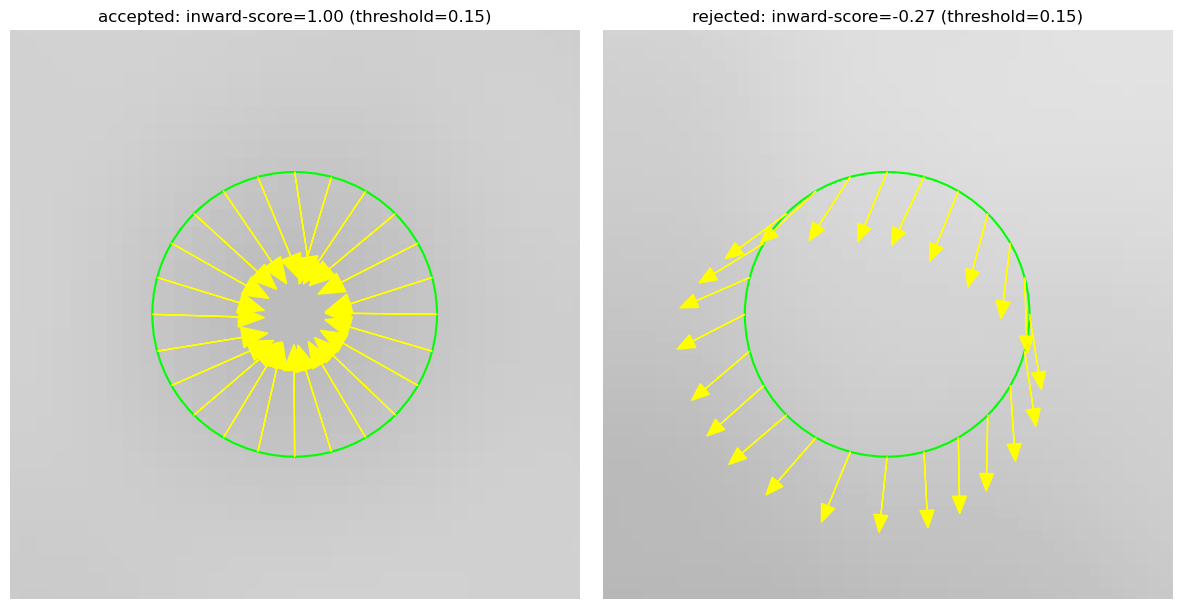

In [33]:
accepted_example, rejected_example, example_tile = None, None, None
for t in eval_tiles[:15]:
    raw_mask = raw_data_mask(t['dem'])
    valid_mask = valid_data_mask(t['dem'])
    dem_smooth = masked_gaussian(t['dem'], raw_mask, SIGMA_SMOOTH)
    for cy, cx, r, s in detect_B_watershed(t['dem']):
        score = aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask)
        if score >= B_MIN_INWARD and accepted_example is None:
            accepted_example = (cy, cx, r, score, dem_smooth, valid_mask)
        if score < B_MIN_INWARD and rejected_example is None:
            rejected_example = (cy, cx, r, score, dem_smooth, valid_mask)
    if accepted_example and rejected_example:
        break

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, example, title in zip(ax, [accepted_example, rejected_example], ['accepted', 'rejected']):
    if example is None:
        a.set_title(f'no {title} example found in first 15 tiles'); a.axis('off'); continue
    cy, cx, r, score, dem_s, vmask = example
    dy, dx = np.gradient(dem_s)
    a.imshow(dem_s, cmap='gray')
    a.add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.5))
    for ang in np.linspace(0, 2*np.pi, 24, endpoint=False):
        py, px = cy + r*np.sin(ang), cx + r*np.cos(ang)
        pyi, pxi = int(round(py)), int(round(px))
        if 0 <= pyi < dem_s.shape[0] and 0 <= pxi < dem_s.shape[1]:
            gy, gx = -dy[pyi, pxi], -dx[pyi, pxi]
            norm = np.hypot(gy, gx) + 1e-9
            a.arrow(px, py, gx/norm*5, gy/norm*5, color='yellow', head_width=1.2, head_length=1.5)
    a.set_xlim(cx-2*r, cx+2*r); a.set_ylim(cy+2*r, cy-2*r)
    a.set_title(f'{title}: inward-score={score:.2f} (threshold={B_MIN_INWARD})')
    a.axis('off')
plt.tight_layout(); plt.show()


In [34]:
evaluate_method(detect_B_aspect, label='B sobel watershed + aspect filter')

=== B sobel watershed + aspect filter ===
precision : 0.42
recall    : 0.60
F1        : 0.50
TP=1948   FP=2670   FN=1284


### Code Structure

```
evaluate_method(detect_B_aspect, ...)
└─ for each of the 100 tiles:
   ├─ detect_fn(dem)  ==  detect_B_aspect(dem)
   │  ├─ raw_data_mask(dem)
   │  ├─ valid_data_mask(dem) → calls raw_data_mask(dem) again itself
   │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  ├─ detect_B_watershed(dem)   ← runs the whole watershed method first
   │  │  ├─ raw_data_mask(dem)
   │  │  ├─ valid_data_mask(dem)
   │  │  ├─ masked_gaussian(dem, raw_mask, sigma)
   │  │  ├─ sobel_edge(dem_smooth, valid_mask)
   │  │  │  └─ sobel(dem_smooth)
   │  │  ├─ normalize(edge, ...)
   │  │  ├─ soft_threshold(normalized_edge, valid_mask)   → score_rim
   │  │  └─ watershed_on_gradient(score_rim, valid_mask)
   │  │     ├─ h_minima(edge_search, B_H_MIN)
   │  │     ├─ label(minima)
   │  │     ├─ watershed(edge_search, markers, mask)
   │  │     ├─ for each segment:
   │  │     │  ├─ regionprops(segments)
   │  │     │  └─ circularity(area, perimeter)
   │  │     └─ circle_nms(detections)                     → raw B detections
   │  └─ filter_by_aspect(detections, dem_smooth, valid_mask)   ← then cleans them up
   │     └─ for each detection:
   │        └─ aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask)
   │           └─ samples the downslope direction at 24 points around the ring
   └─ match_detailed(dets, craters)
└─ (after all 100 runs) compute precision/recall/F1 + print
```

## All methods side by side, 3 example tiles

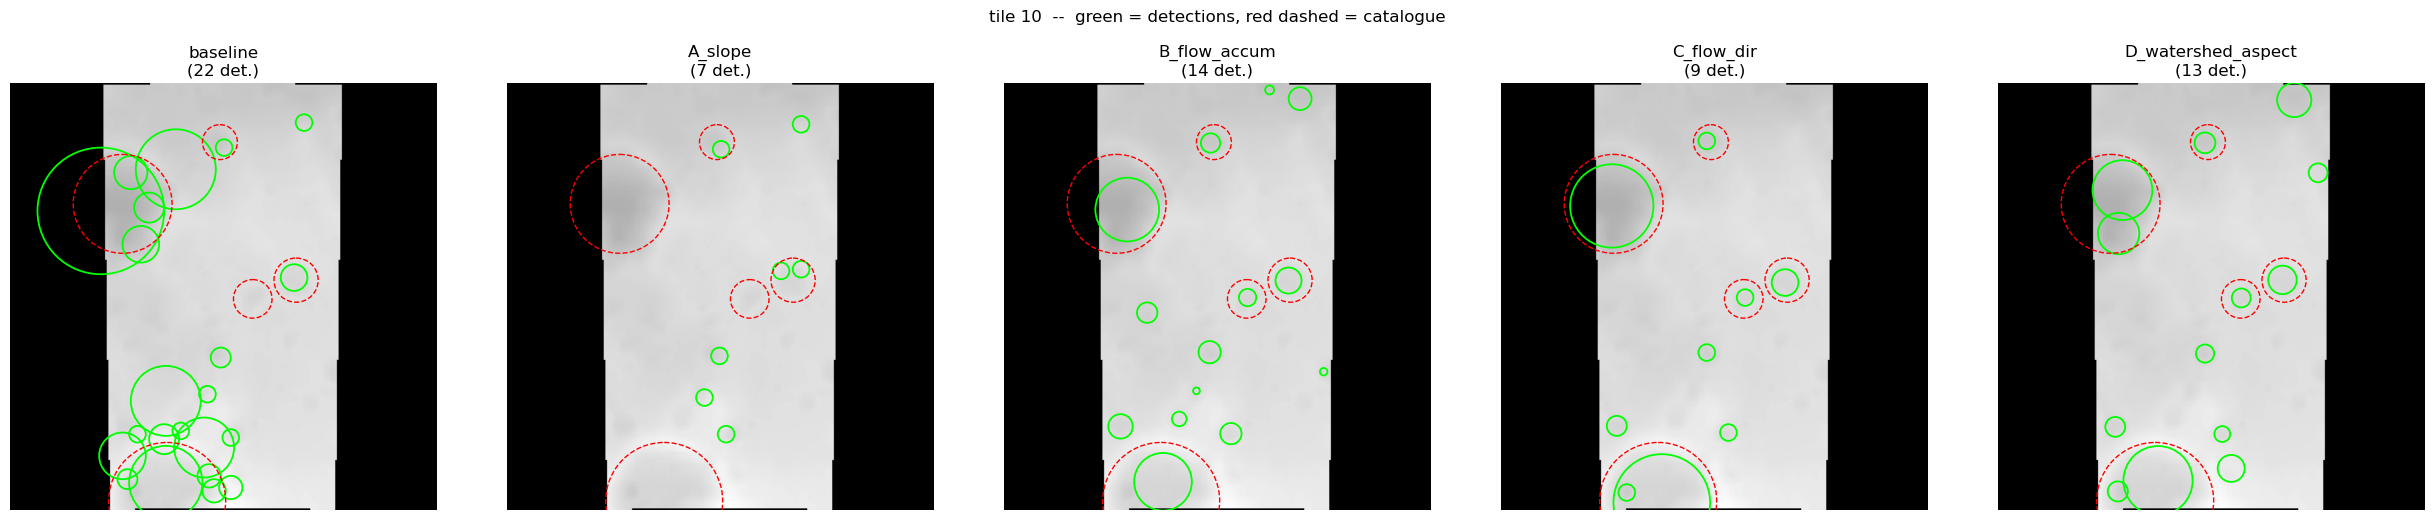

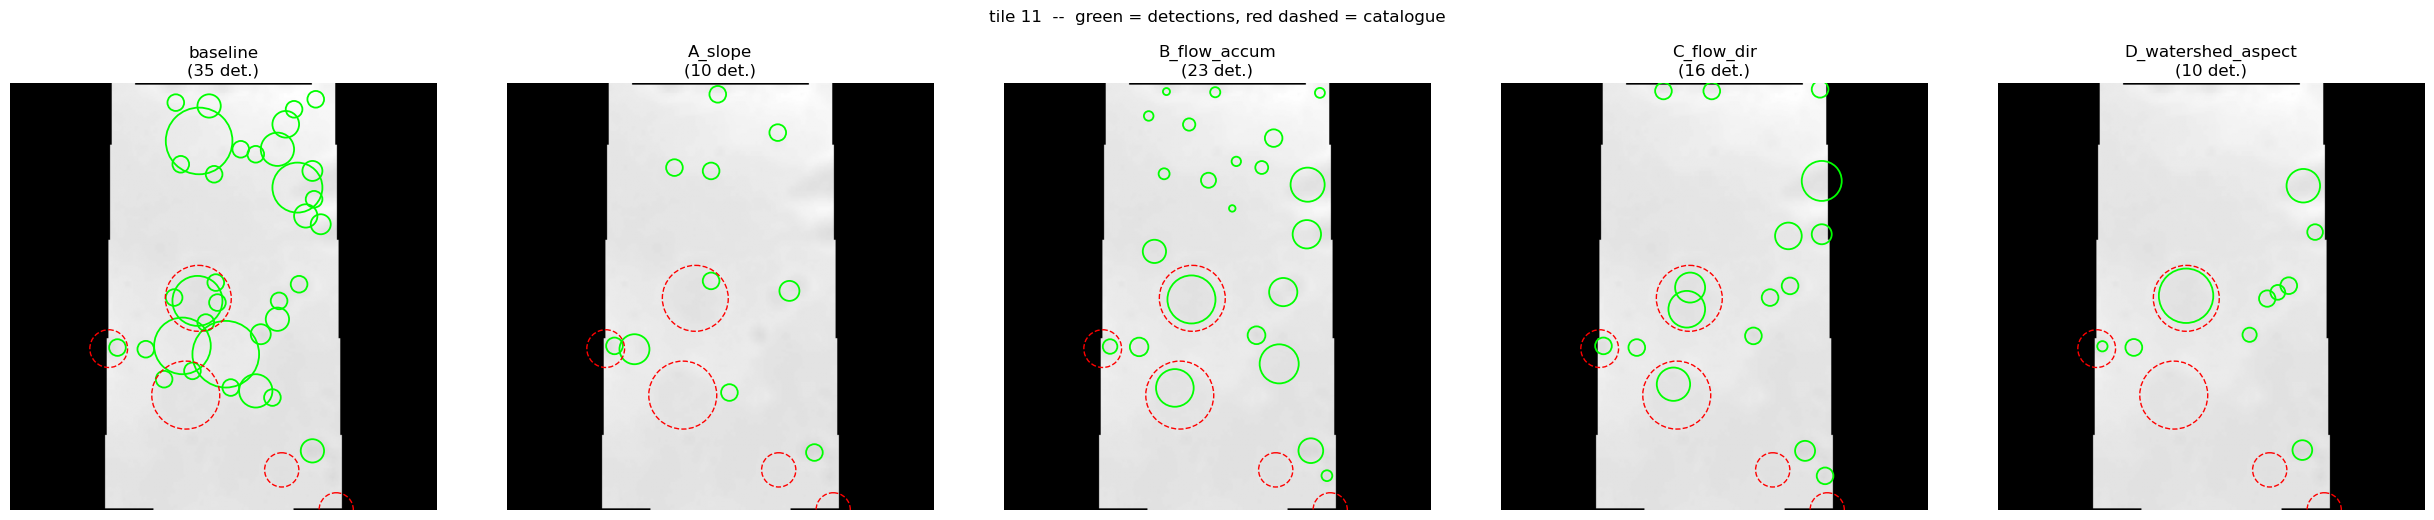

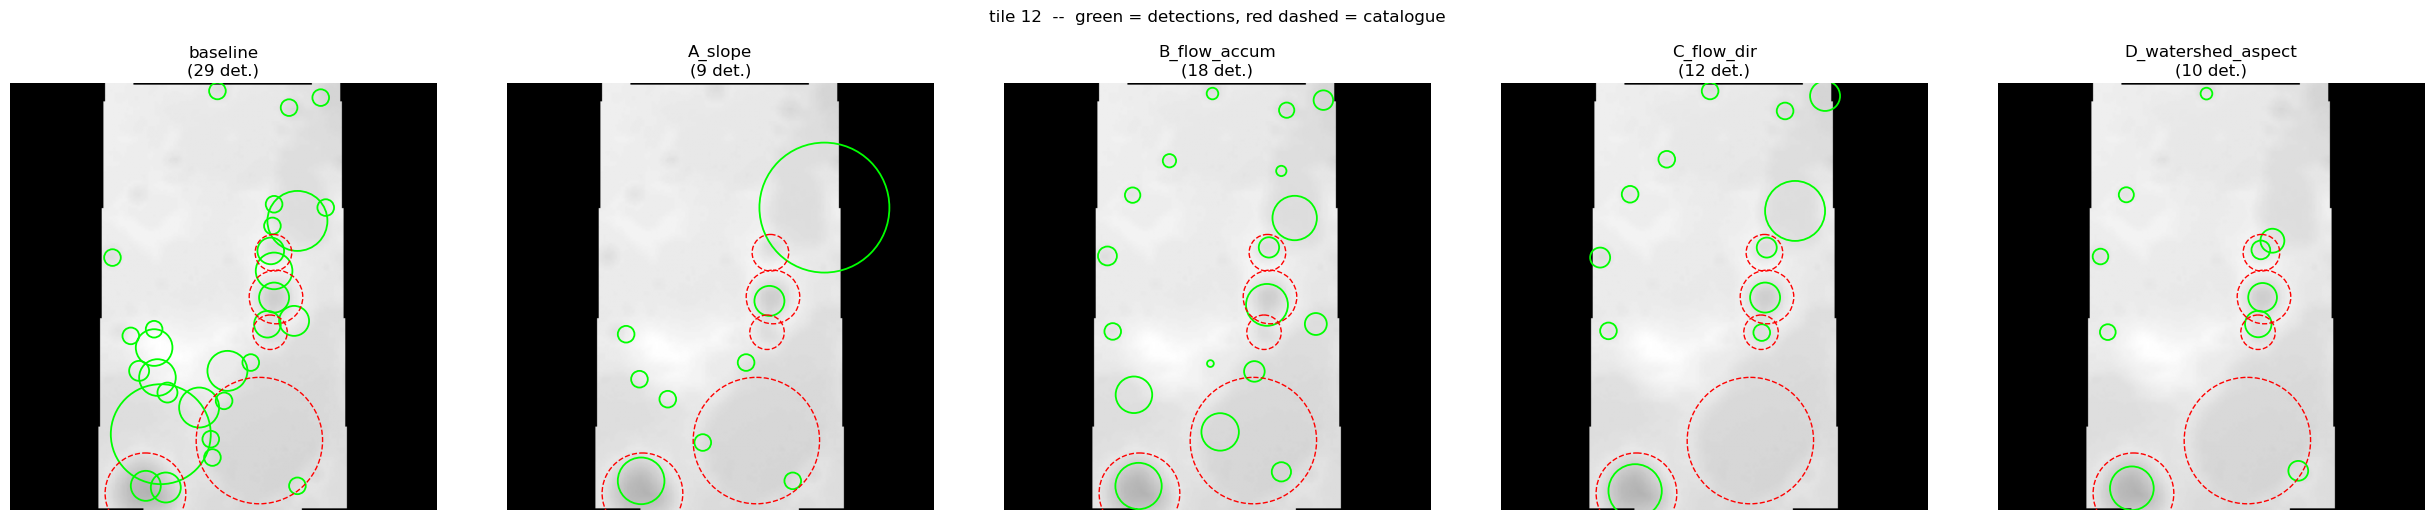

In [35]:
# every method we've built, keyed by name, in the same order as the sections above
DEMO_METHODS = {
    'baseline': detect_baseline,
    'A_slope': detect_A_slope,
    'B_flow_accum': detect_C_flow_accum,
    'C_flow_dir': detect_E_flow_direction,
    'D_watershed_aspect': detect_B_aspect,
}

DEMO_TILES = eval_tiles[10:13] # tiles 10, 11, 12

# run every method on these 3 tiles once, so the plotting function below doesn't
# re-run detection every time it's called
demo_results = {t['idx']: {name: fn(t['dem']) for name, fn in DEMO_METHODS.items()}
                 for t in DEMO_TILES}

# draws all 5 methods' detections (green) against the real catalogue (red dashed) for one tile
def plot_tile_comparison(t):
    combo = demo_results[t['idx']]
    fig, ax = plt.subplots(1, 5, figsize=(25, 5))
    for a, name in zip(ax, combo.keys()):
        a.imshow(t['dem'], cmap='gray')
        for cy, cx, r, s in combo[name]:
            a.add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.3))
        for _, c in t['craters'].iterrows():
            a.add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2,
                               fill=False, color='red', lw=1.0, linestyle='--'))
        a.set_title(f"{name}\n({len(combo[name])} det.)")
        a.axis('off')
    fig.suptitle(f"tile {t['idx']}  --  green = detections, red dashed = catalogue", y=1.03)
    plt.tight_layout()
    plt.show()

for t in DEMO_TILES:
    plot_tile_comparison(t) # calls plot_tile_comparison()

## Combined

Two variants: (1) watershed and flow direction must BOTH agree, (2) watershed, flow accumulation, AND flow direction must ALL THREE agree. A crater counts only if every required method independently finds it at (roughly) the same place and size.

In [36]:
# pools detections from several methods, groups overlapping ones into clusters, and keeps a
# cluster only if at least min_agree DIFFERENT methods contributed to it. the kept detection's
# centre/radius is the median across the cluster (robust to one method being a bit off)
def cluster_consensus(results_for_tile, min_agree, dist_frac=0.5):
    pooled = []
    for name, dets in results_for_tile.items():
        for cy, cx, r, s in dets:
            pooled.append((cy, cx, r, s, name)) # keep track of which method made this detection

    used = [False]*len(pooled)
    consensus = []
    for i, (cy, cx, r, s, name) in enumerate(pooled):
        if used[i]:
            continue
        cluster = [(cy, cx, r, name)]
        used[i] = True
        for j in range(i+1, len(pooled)): # gather every other detection that overlaps this one
            if used[j]:
                continue
            cy2, cx2, r2, s2, name2 = pooled[j]
            if np.hypot(cy-cy2, cx-cx2) < dist_frac*(r+r2):
                cluster.append((cy2, cx2, r2, name2))
                used[j] = True
        distinct_methods = {c[3] for c in cluster} # how many DIFFERENT methods are in this cluster
        if len(distinct_methods) >= min_agree:
            cys = np.median([c[0] for c in cluster])
            cxs = np.median([c[1] for c in cluster])
            rs = np.median([c[2] for c in cluster])
            consensus.append((cys, cxs, rs, len(distinct_methods)))
    return consensus

def detect_consensus(dem, methods, min_agree):
    results = {name: fn(dem) for name, fn in methods.items()} # calls each method in the given set
    return cluster_consensus(results, min_agree) # calls cluster_consensus()

# variant 1: watershed + flow direction, both required
CONSENSUS_METHODS_BE = {
    'B_aspect': detect_B_aspect,
    'E_flow_dir': detect_E_flow_direction,
}
print(f"Consensus 1: both required: {list(CONSENSUS_METHODS_BE.keys())}")
evaluate_method(lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BE, 2),
                label='consensus: watershed & flow direction (both required)')

# variant 2: watershed + flow accumulation + flow direction, all three required
CONSENSUS_METHODS_BCE = {
    'B_aspect': detect_B_aspect,
    'C_flow_accum': detect_C_flow_accum,
    'E_flow_dir': detect_E_flow_direction,
}
print(f"Consensus 2: all three required: {list(CONSENSUS_METHODS_BCE.keys())}")
evaluate_method(lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BCE, 3),
                label='consensus: watershed & flow accumulation & flow direction (all three required)')


Consensus 1: both required: ['B_aspect', 'E_flow_dir']


=== consensus: watershed & flow direction (both required) ===
precision : 0.57
recall    : 0.53
F1        : 0.55
TP=1708   FP=1281   FN=1524
Consensus 2: all three required: ['B_aspect', 'C_flow_accum', 'E_flow_dir']


=== consensus: watershed & flow accumulation & flow direction (all three required) ===
precision : 0.60
recall    : 0.49
F1        : 0.54
TP=1573   FP=1065   FN=1659


## Radius bias per method

In [37]:
# the methods we actually have -- no consensus, no lenient/strict split, just this
BIAS_METHODS = {
    'baseline': detect_baseline,
    'A_slope': detect_A_slope,
    'C_flow_accum': detect_C_flow_accum,
    'E_flow_dir': detect_E_flow_direction,
    'B_watershed': detect_B_watershed,
    'B_aspect': detect_B_aspect,
}

# for every method: how far off is the detected radius from the true catalogue radius,
# averaged over every matched true positive. ratio > 1 means the method under-estimates size.
# the two percentages are the same fact from both sides: a mean ratio of 1.5 means the detected
# radius is 1/1.5 = 67% of the true one (33% too small) and has to be scaled up by 50% to match
def radius_bias_table(D_xy=1.8, D_r=1.0):
    rows = []
    for name, fn in BIAS_METHODS.items():
        ratios = []
        for t in eval_tiles:
            dets = fn(t['dem']) # calls this method's detect function
            tp_pairs, fp, fn_radii = match_detailed(dets, t['craters'], D_xy, D_r) # calls match_detailed()
            ratios += [tr / r for tr, r in tp_pairs] # catalogue_r / detected_r per match
        if ratios:
            mean_ratio = np.mean(ratios)
            direction = 'under-estimates' if mean_ratio > 1 else 'over-estimates'
            rows.append({'method': name, 'mean ratio': round(mean_ratio, 2),
                          'median ratio': round(np.median(ratios), 2),
                          'std': round(np.std(ratios), 2),
                          'under-estimates by (%)': round((1 - 1/mean_ratio)*100, 1),
                          'scale-up needed (%)': round((mean_ratio-1)*100, 1),
                          'direction': direction, 'n_matched': len(ratios)})
        else:
            rows.append({'method': name, 'mean ratio': np.nan, 'median ratio': np.nan,
                          'std': np.nan, 'bias (%)': np.nan, 'direction': '(no matches)', 'n_matched': 0})
    return pd.DataFrame(rows).set_index('method')

radius_bias_table() # calls radius_bias_table()

,mean ratio,median ratio,std,under-estimates by (%),scale-up needed (%),direction,n_matched
method,,,,,,,
baseline,1.43,1.42,0.29,30.0,43.0,under-estimates,1471
A_slope,1.53,1.63,0.38,34.5,52.6,under-estimates,842
C_flow_accum,1.53,1.54,0.26,34.7,53.2,under-estimates,1796
E_flow_dir,1.59,1.61,0.24,37.2,59.2,under-estimates,1958
B_watershed,1.52,1.56,0.29,34.3,52.1,under-estimates,2041
B_aspect,1.55,1.58,0.27,35.3,54.6,under-estimates,1948


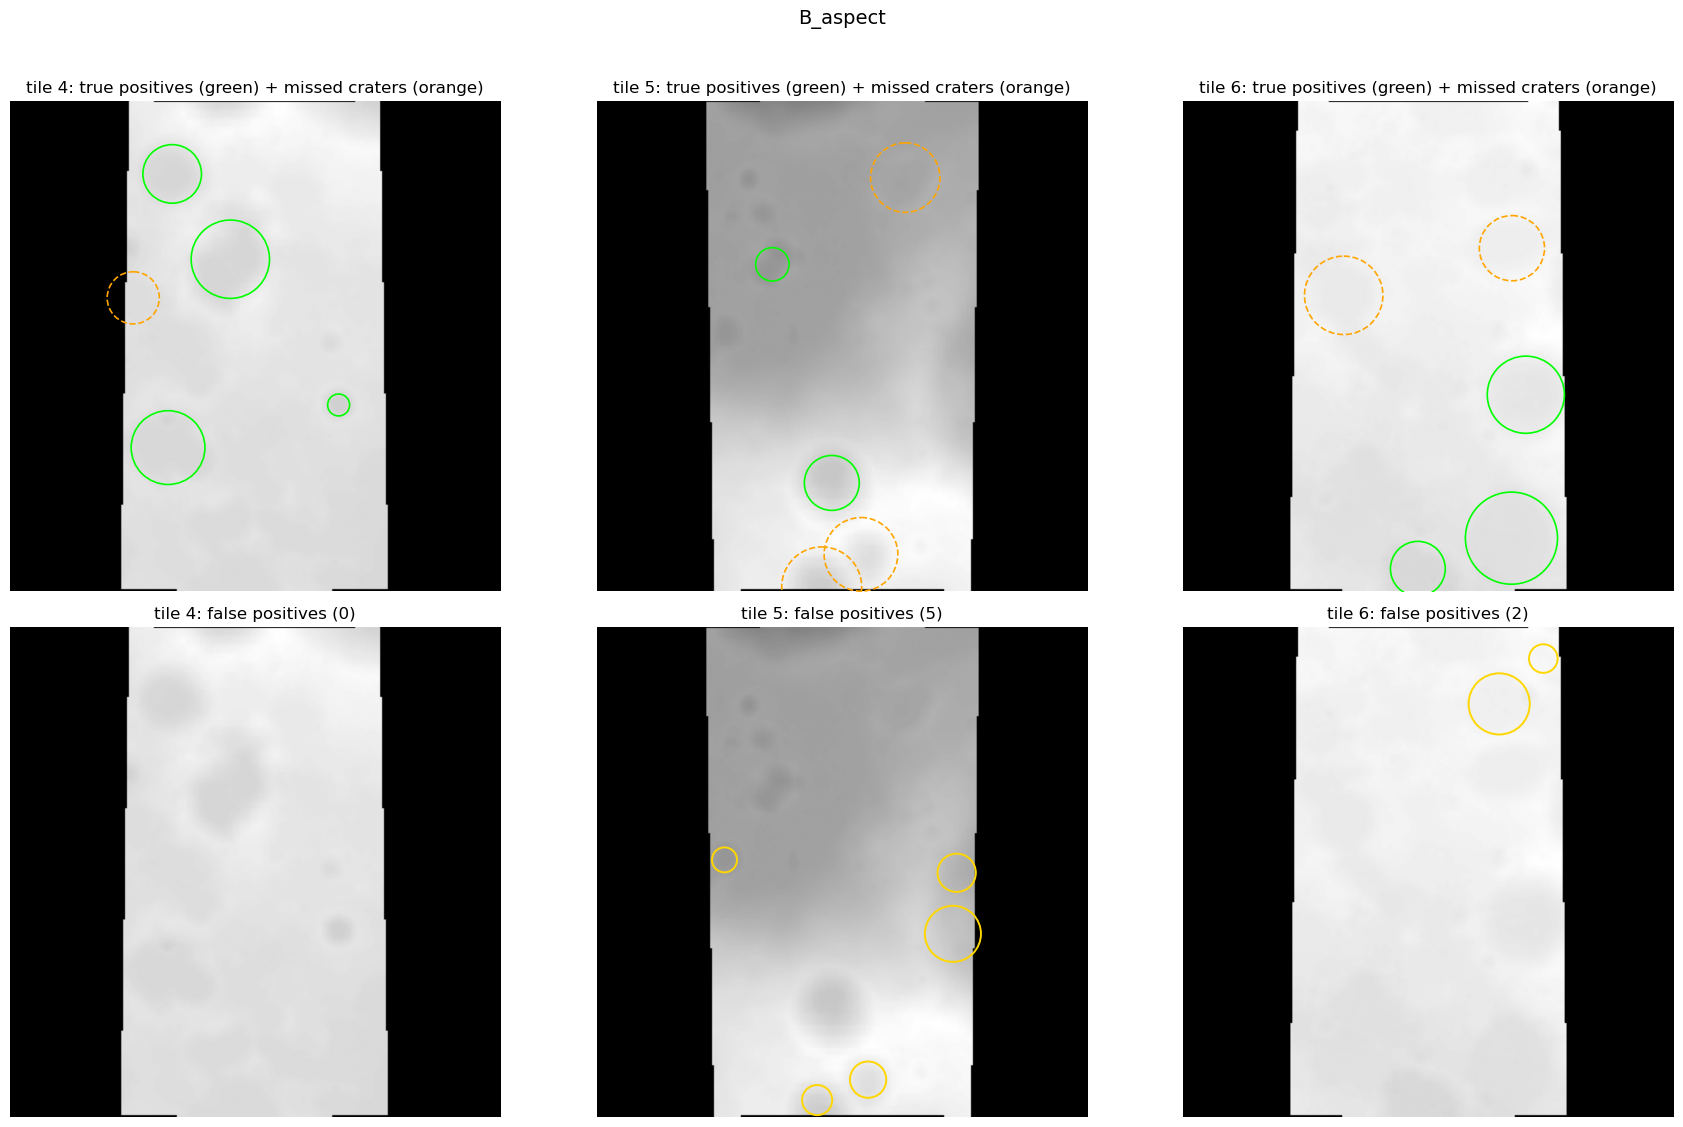

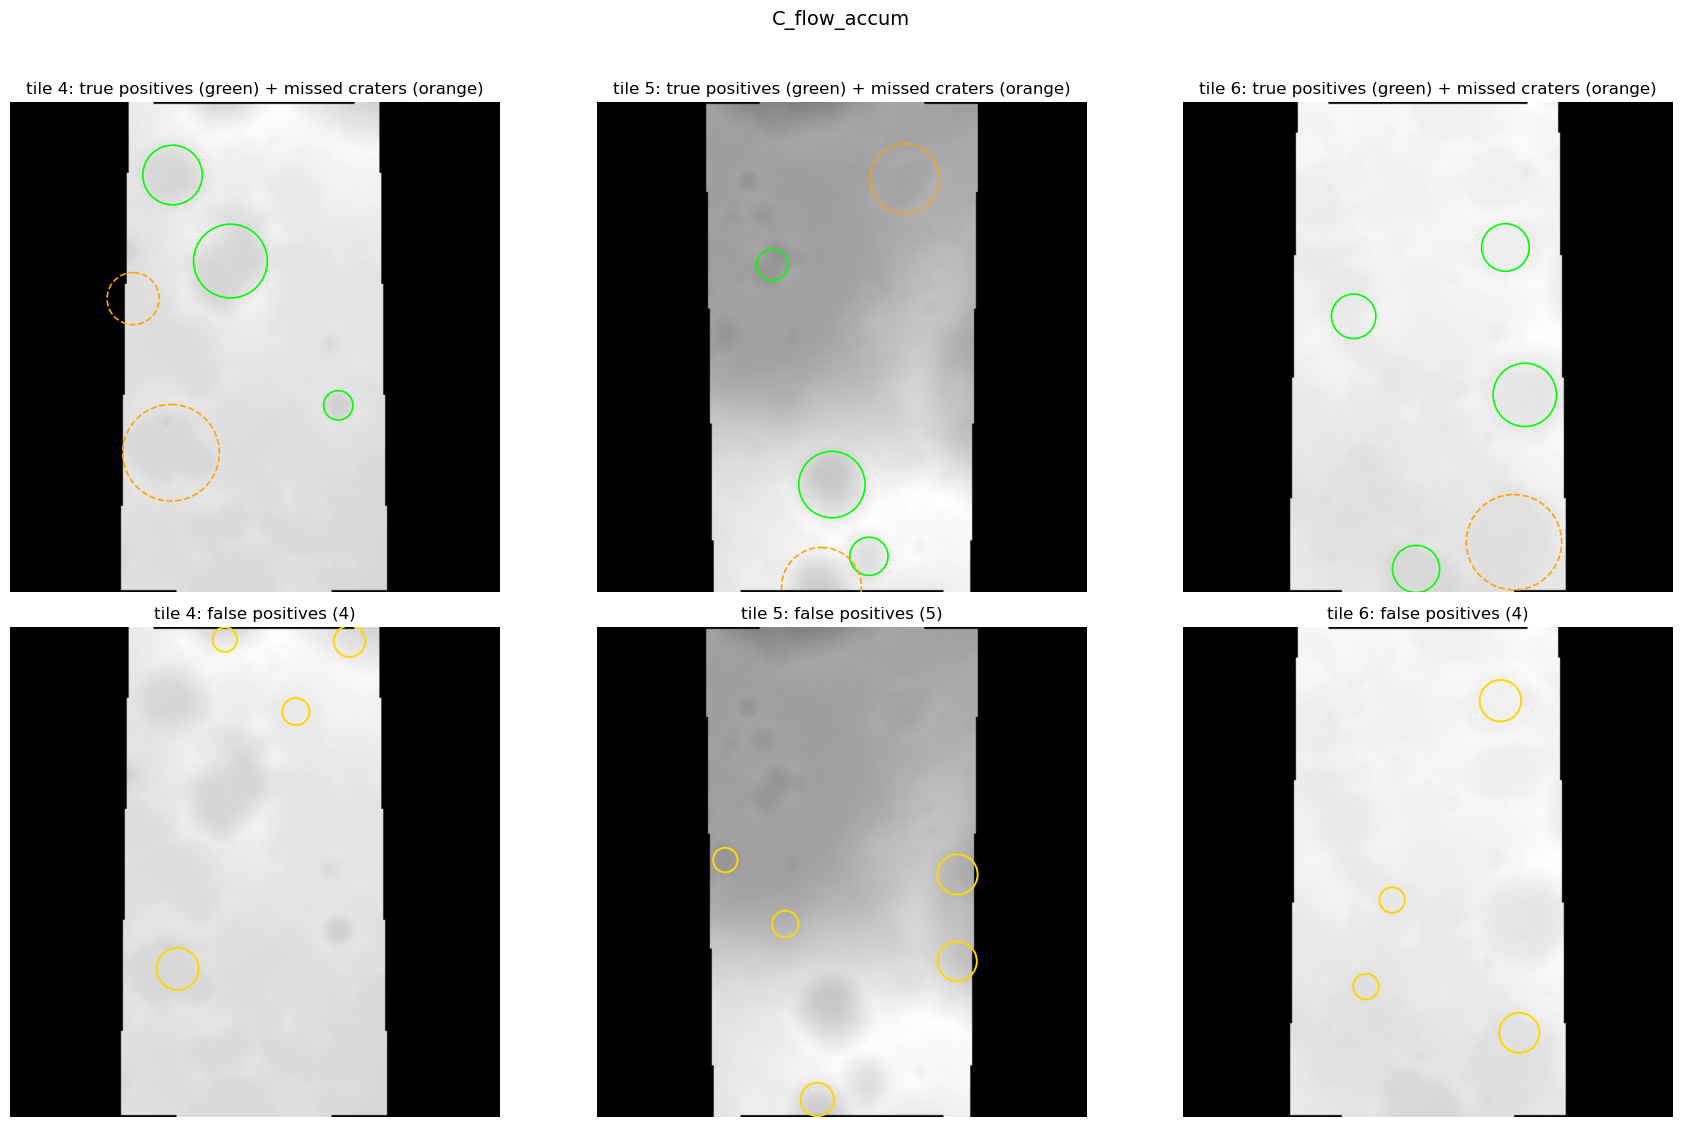

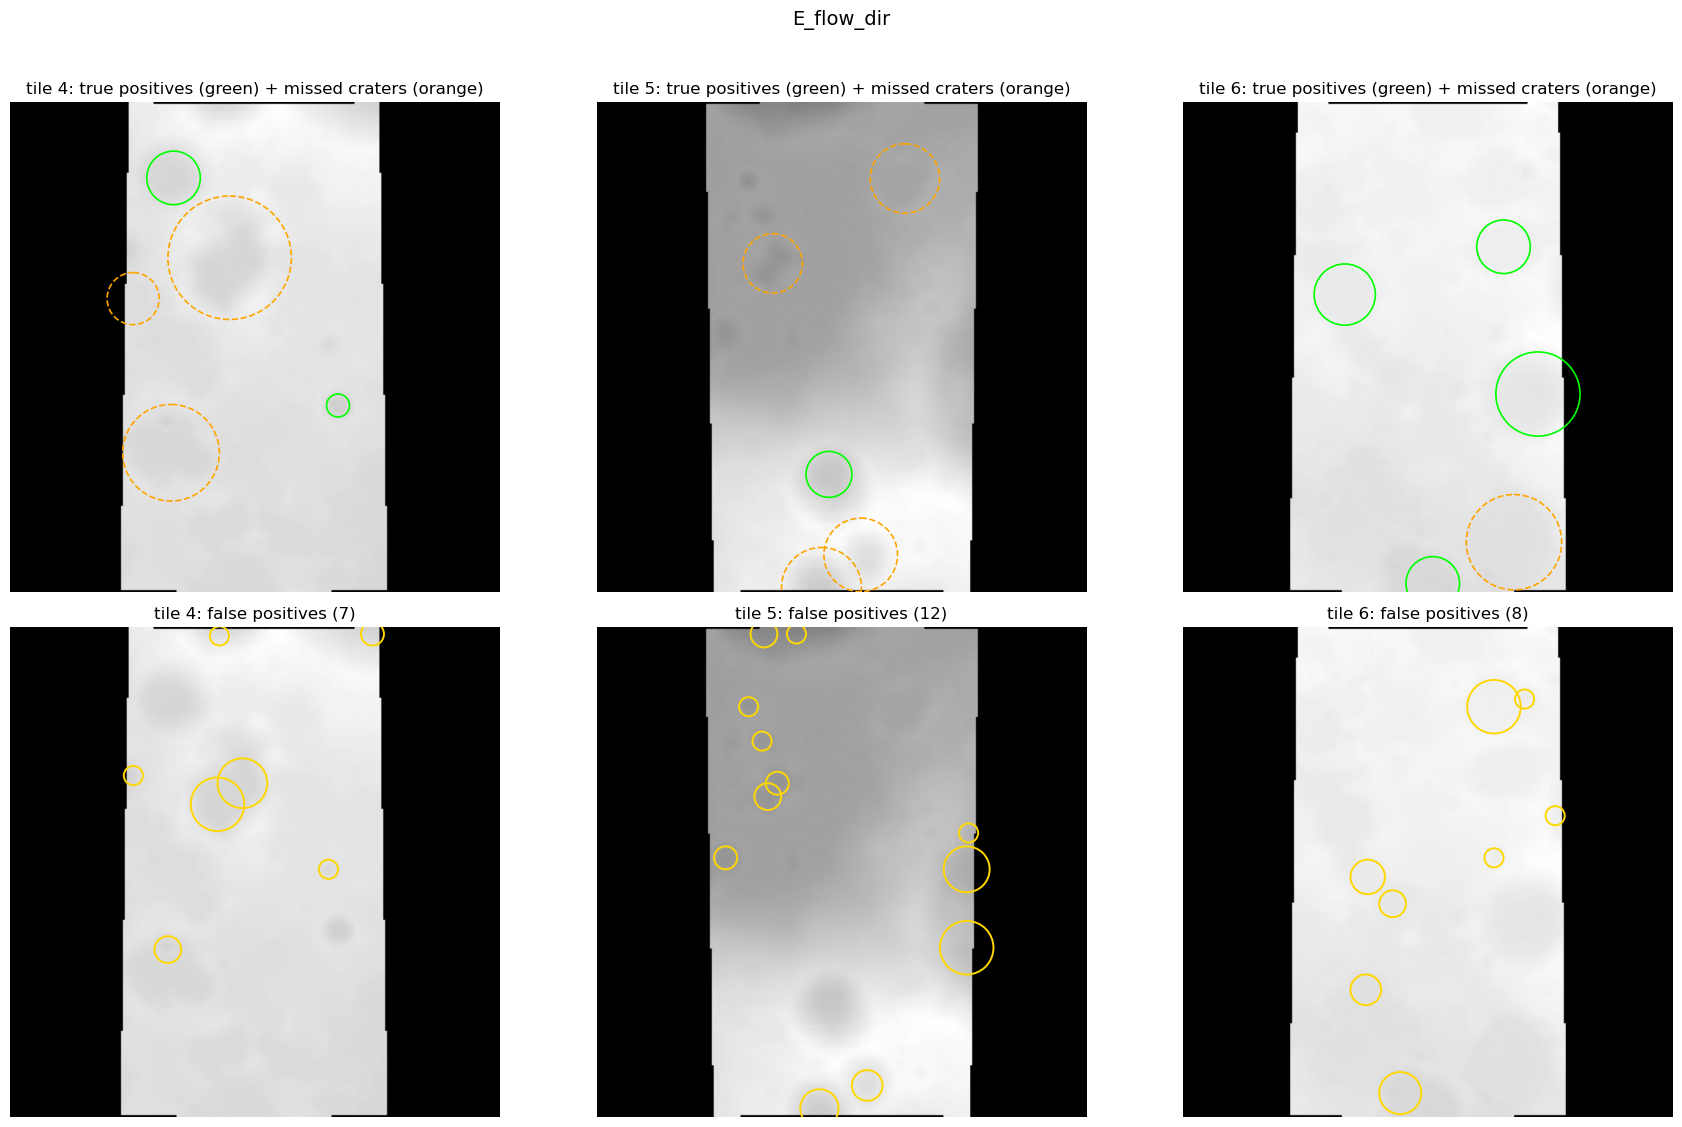

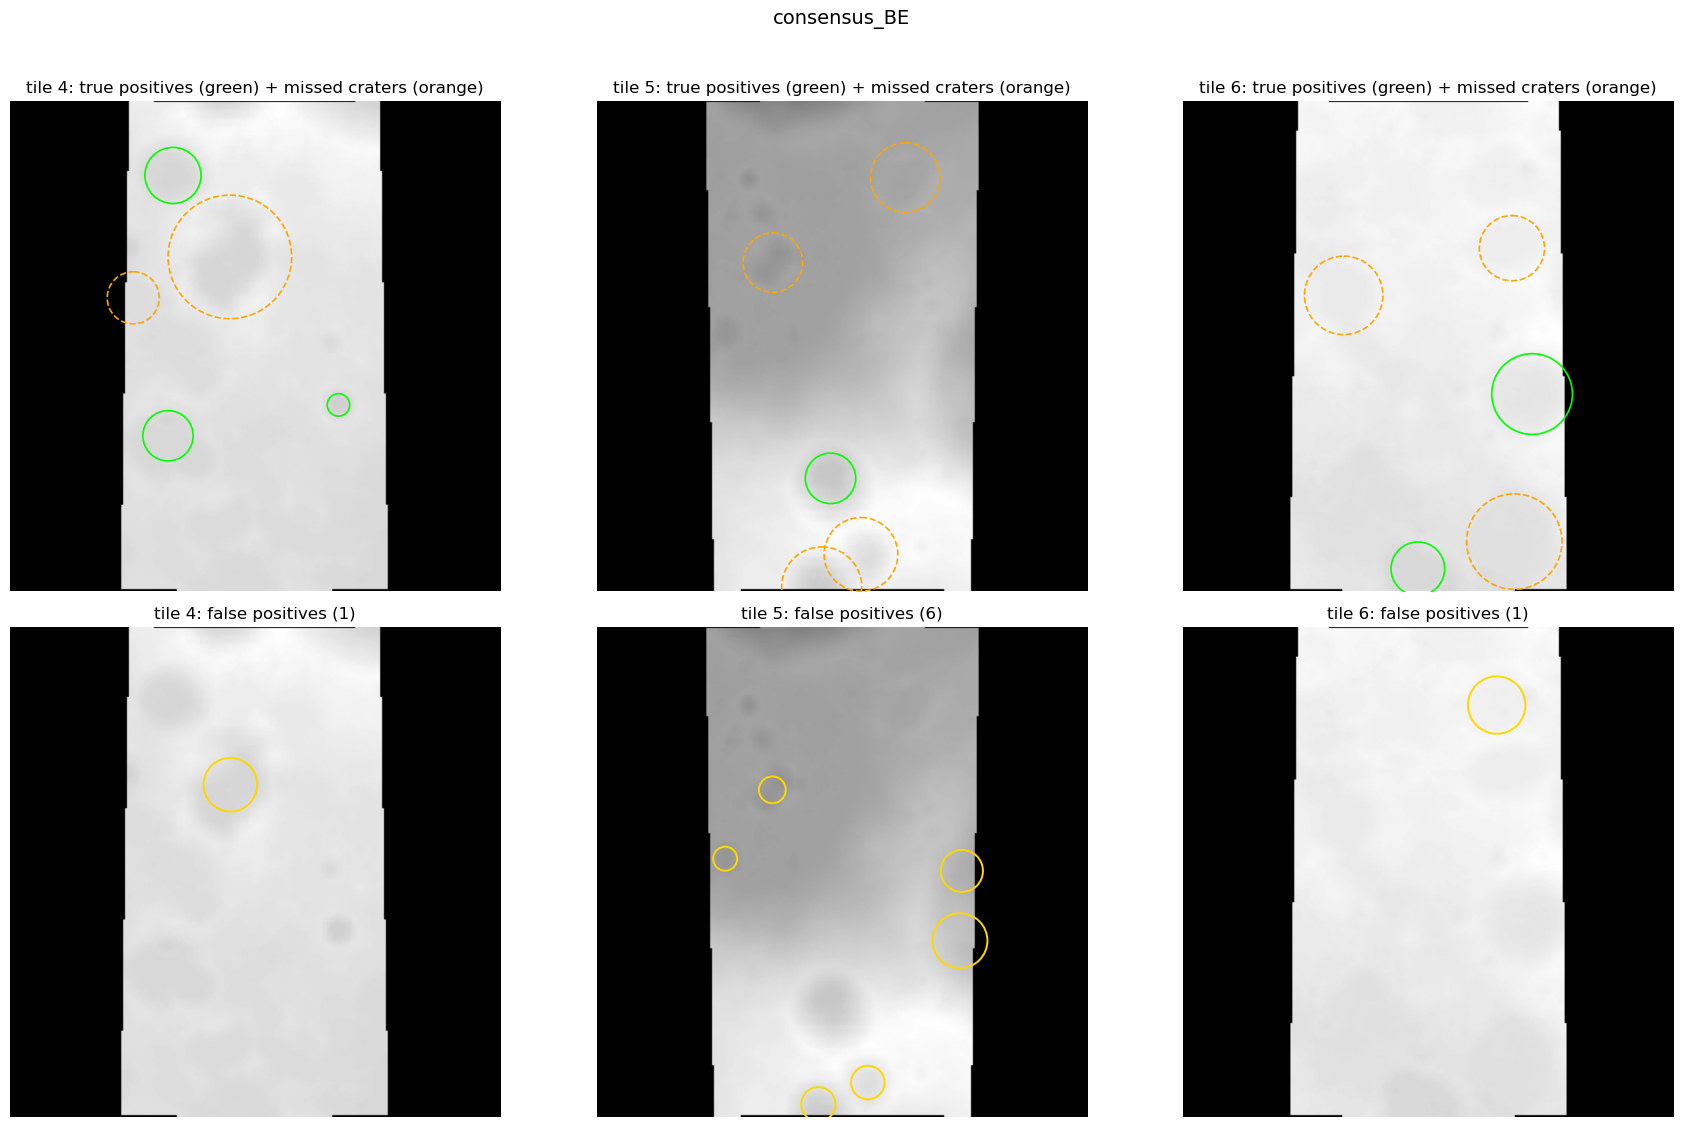

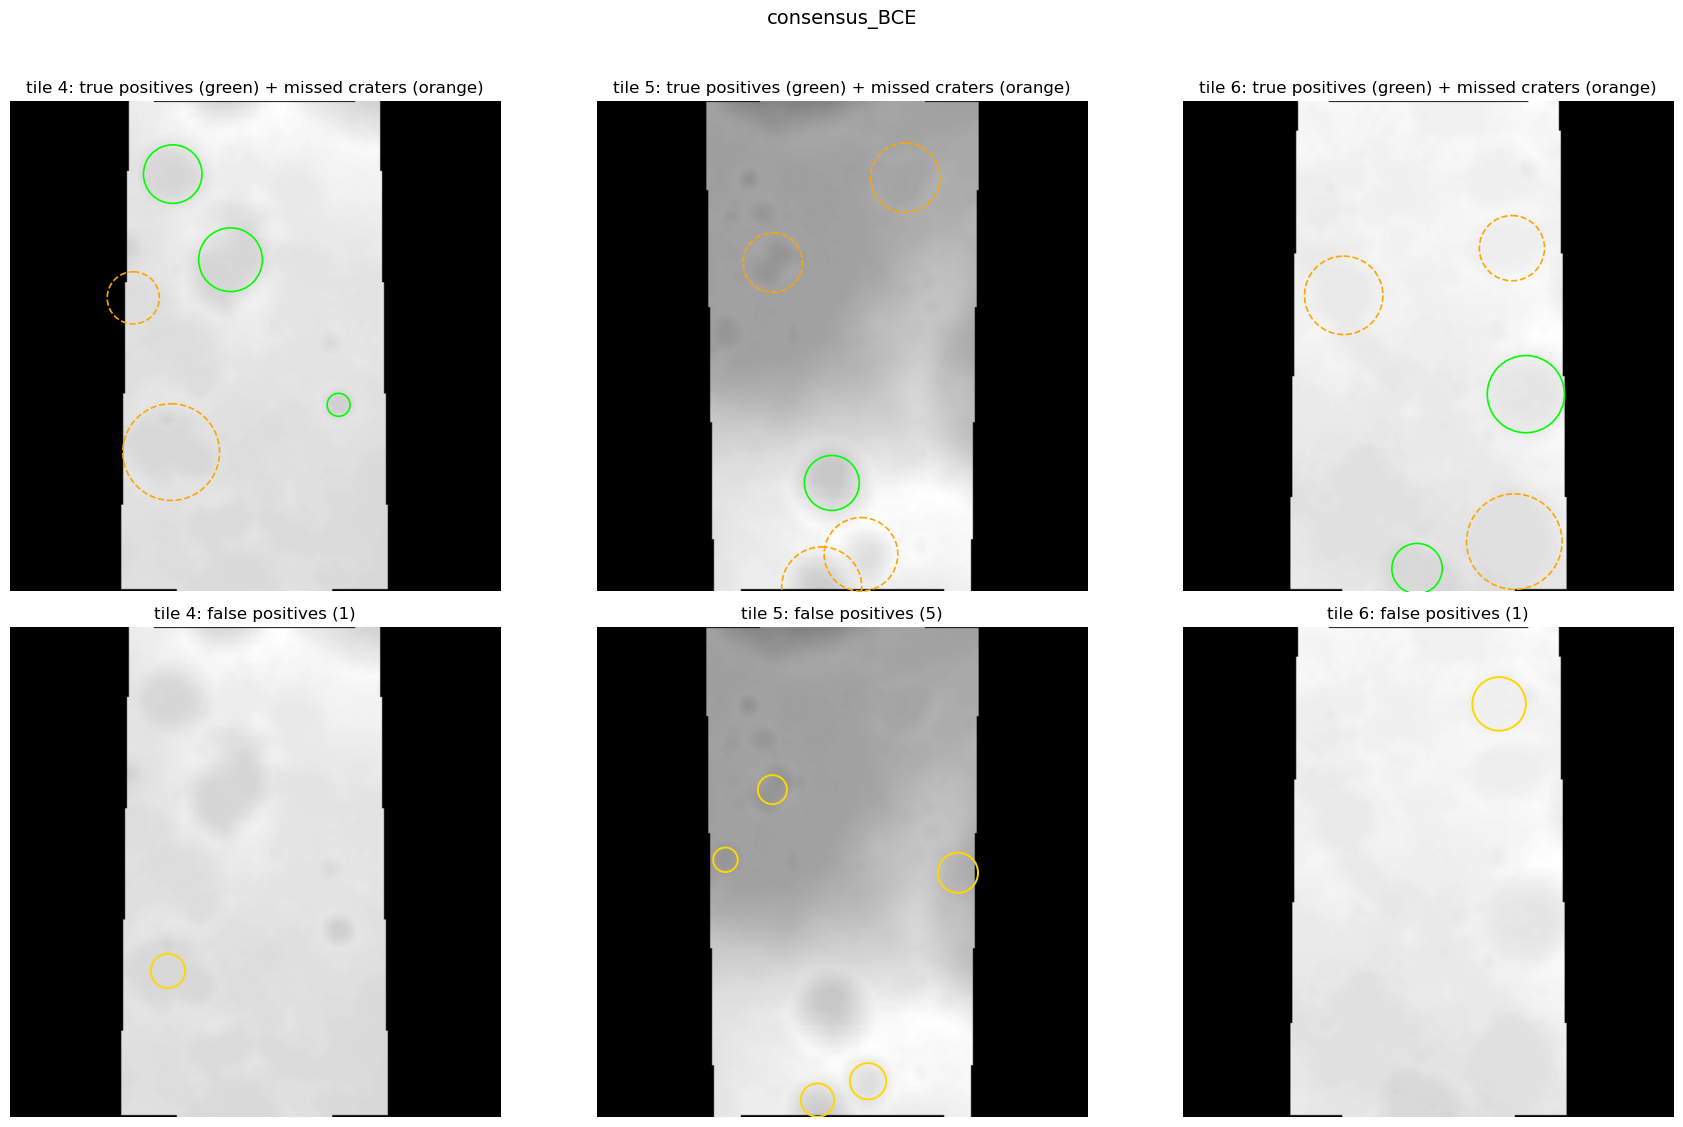

In [38]:
EXAMPLE_TILES = eval_tiles[4:7]

# einheitliches Interface für alle Methoden: name -> function(tile) -> detections
METHODS_FOR_PLOTTING = {
    'B_aspect': lambda t: detect_B_aspect(t['dem']),
    'C_flow_accum': lambda t: detect_C_flow_accum(t['dem']),
    'E_flow_dir': lambda t: detect_E_flow_direction(t['dem']),
    'consensus_BE': lambda t: detect_consensus(t['dem'], CONSENSUS_METHODS_BE, 2),
    'consensus_BCE': lambda t: detect_consensus(t['dem'], CONSENSUS_METHODS_BCE, 3),
}

def classify_detections_ranged(dets, cat, D_xy=1.8, D_r=1.0):
    # range-filtering happens ONCE, here -- both what gets plotted and what gets
    # scored come from the same filtered lists, so nothing can silently vanish
    # from evaluation while still showing up on the plot
    truth = [(c['x'], c['y'], c['Diameter (pix)']/2) for _, c in cat.iterrows()
             if SCAN_R_MIN <= c['Diameter (pix)']/2 <= SCAN_R_MAX]
    dets = [d for d in dets if SCAN_R_MIN <= d[2] <= SCAN_R_MAX]
    matched = set()
    tp_dets, fp_dets = [], []
    for cy, cx, r, s in sorted(dets, key=lambda d: -d[3]):
        found = False
        for k, (tx, ty, tr) in enumerate(truth):
            if k in matched:
                continue
            if ((cx-tx)**2+(cy-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                matched.add(k)
                found = True
                break
        if found:
            tp_dets.append((cy, cx, r, s))
        else:
            fp_dets.append((cy, cx, r, s))
    fn_craters = [(tx, ty, tr) for k, (tx, ty, tr) in enumerate(truth) if k not in matched] # missed catalogue craters
    return tp_dets, fp_dets, fn_craters

def plot_method_examples(name, method_fn, tiles=EXAMPLE_TILES):
    fig, ax = plt.subplots(2, len(tiles), figsize=(6*len(tiles), 11))
    for col, t in enumerate(tiles):
        dets = method_fn(t)
        tp_dets, fp_dets, fn_craters = classify_detections_ranged(dets, t['craters'])

        # row 1: true positives (green) + missed craters / false negatives (orange) -- no raw
        # catalogue overlay anymore, and no unfiltered/unscored detections sneaking in
        a = ax[0, col]
        a.imshow(t['dem'], cmap='gray')
        for cy, cx, r, s in tp_dets:
            a.add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.2))
        for tx, ty, tr in fn_craters:
            a.add_patch(Circle((tx, ty), tr, fill=False, color='orange', lw=1.2, linestyle='--'))
        a.set_title(f"tile {t['idx']}: true positives (green) + missed craters (orange)")
        a.axis('off')

        # row 2: nur die Fehlalarme (gelb)
        a = ax[1, col]
        a.imshow(t['dem'], cmap='gray')
        for cy, cx, r, s in fp_dets:
            a.add_patch(Circle((cx, cy), r, fill=False, color='gold', lw=1.4))
        a.set_title(f"tile {t['idx']}: false positives ({len(fp_dets)})")
        a.axis('off')
    fig.suptitle(name, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

for name, fn in METHODS_FOR_PLOTTING.items():
    plot_method_examples(name, fn)